# Team29 | Chest X-ray Report Generation (final experiment)


**Inputs.** Set `SOURCE` in section 02 to the V1 results export (ZIP or folder). It must contain `image_features.npz`, the train/val/test study manifests, `validation_predictions.csv`, `image_audit.csv` and `saved_generator/`. Section 03a builds the XRV scores (`Team29/xrv_features_chex.npz`) and section 03c builds the pooled XRV features (`Team29/xrv_pooled_chex.npz`) from `processed_images.zip`. Every run writes to a new timestamped folder; earlier runs are never overwritten.

**Model.** FLAN-T5-small decoder. Each X-ray view enters as 4 learned visual tokens built from a frozen ImageNet ResNet18 global vector. The text prompt holds the clinical indication plus up to 3 "image findings" tags. The tags come from a small classifier trained on IU training studies, on top of 1024-D features from torchxrayvision's CheXpert-only DenseNet121 (`densenet121-res224-chex`). After generation, a finding sentence is added when the classifier is highly confident and the report does not already state it (section 07b).

**Why CheXpert-only weights.** The first tagged runs used `densenet121-res224-all`, which was trained on OpenI, the same IU X-Ray collection used here. That tagger may have learned the labels of our validation and test images, so every result that used it is superseded.

**Training.** Starts from pretrained FLAN-T5-small. 2 warmup epochs train the adapter with T5 frozen, then up to 15 joint epochs with a lower T5 learning rate. Studies whose reports mention an abnormal finding are sampled 5 times more often. The checkpoint is selected by validation token loss.

**Evaluation.** BLEU, ROUGE-L, METEOR, report diversity, a paired image-swap test, and a finding-level count on validation; the same metrics once on test. Text metrics do not measure clinical correctness.

**Limits.** Splits are by study, not by patient. The test split was evaluated several times during development (see section 10). Finding detection is still weak.

## 01 | Dependencies — run once in a fresh session
Avoid upgrading numpy, torch, torchvision or sklearn in an active session. Evaluation runs in a fresh Python subprocess to avoid the prior mixed sklearn imports. If Colab requests a restart, do so before continuing.


In [25]:
%pip -q install --only-binary=tokenizers "transformers==4.57.1" "tokenizers==0.22.1" sentencepiece safetensors "sacrebleu==2.5.1" "rouge-score==0.1.2" nltk


## 02 | EDIT PATHS HERE
For a new runtime, upload the old results ZIP or put it in Drive. /content paths from an earlier disconnected runtime no longer exist. Mount Drive to persist the new results. SOURCE can also be /content/your_export.zip.


In [26]:
from pathlib import Path
USE_DRIVE = True
if USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')

SOURCE_NAME = '20261025_170217_459180_export (1).zip'
search_dirs = [Path('/content/drive/MyDrive/Team29'), Path('/content/drive/MyDrive')]
found = []
for d in search_dirs:
    if d.exists():
        found = sorted(p for p in d.glob('**/*') if SOURCE_NAME in p.name and (p.suffix == '.zip' or p.is_dir()))
    if found: break
print('found:', [str(p) for p in found])
assert found, 'Upload the V1 export ZIP to Drive/Team29 first'
SOURCE = found[0]
print('SOURCE =', SOURCE)
OUTPUT_ROOT = Path('/content/drive/MyDrive/Team29/report_generation_v2') if USE_DRIVE else Path('/content/report_generation_v2')

SEED = 42
BATCH_SIZE = 2
ACCUM = 4
VISUAL_TOKENS = 4
WARMUP_EPOCHS = 2
JOINT_EPOCHS = 15
WARMUP_LR = 1e-3
ADAPTER_LR = 3e-4
TEXT_LR = 1e-5
PATIENCE = 3
TINY_STEPS = 160
CONTINUE_IF_TINY_FAILS = False
BASE_MODEL = 'google/flan-t5-small'
MAX_INPUT = 128
MAX_TARGET = 256
XRV_WEIGHTS = 'densenet121-res224-chex'  # CheXpert only. Do not use '-all': it was trained on OpenI (IU X-Ray).

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
found: ['/content/drive/MyDrive/Team29/20261025_170217_459180_export (1).zip']
SOURCE = /content/drive/MyDrive/Team29/20261025_170217_459180_export (1).zip


## 03 | Read and validate saved artifacts
The test manifest is used only to verify disjoint IDs. Test targets are not read into model training or evaluation. The original cohort is unchanged.


In [27]:
import json, zipfile, tempfile, hashlib, random, time, gc, shutil, sys, subprocess
from datetime import datetime
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader
from tqdm.auto import tqdm
from IPython.display import display
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

def reset_seed():
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
reset_seed()
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if DEVICE.type!='cuda': print('WARNING: running on CPU. Fine for evaluation, too slow for training.')
assert SOURCE.exists(), 'Fix SOURCE in 02. Upload the previous RESULTS ZIP if the old session ended.'
if SOURCE.is_file():
    root=Path(tempfile.mkdtemp(prefix='report_v2_source_'))
    with zipfile.ZipFile(SOURCE) as archive:
        for m in archive.infolist():
            assert (root/m.filename).resolve().is_relative_to(root.resolve()), 'Unsafe ZIP path'
            assert ((m.external_attr >> 16)&0o170000)!=0o120000, 'ZIP symlink'
        archive.extractall(root)
    candidates=[p.parent for p in root.rglob('train_studies.json')]
    assert len(candidates)==1, f'Expected one previous run, found {candidates}'
    OLD=candidates[0]
else: OLD=SOURCE
required=['train_studies.json','val_studies.json','test_studies.json','image_features.npz',
          'validation_predictions.csv','image_audit.csv','saved_generator/config.json',
          'saved_generator/visual_adapter.pt','saved_generator/text_model/config.json']
assert all((OLD/f).is_file() for f in required), f'Missing files: {[f for f in required if not (OLD/f).is_file()]}'
old_config=json.loads((OLD/'saved_generator/config.json').read_text())
assert old_config['image_dimension']==512 and old_config['image_encoder']=='resnet18'
assert old_config['max_input_tokens']==MAX_INPUT and old_config['max_target_tokens']==MAX_TARGET
train=pd.DataFrame(json.loads((OLD/'train_studies.json').read_text()))
val=pd.DataFrame(json.loads((OLD/'val_studies.json').read_text()))
for frame in [train,val]:
    frame['uid']=frame.uid.astype(str)
    assert frame.uid.is_unique
    assert all(len(a)==len(b)>0 for a,b in zip(frame.image_names,frame.view_ids))
test_ids={str(r['uid']) for r in json.loads((OLD/'test_studies.json').read_text())}
assert not set(train.uid)&set(val.uid)
assert not (set(train.uid)|set(val.uid))&test_ids
with np.load(OLD/'image_features.npz',allow_pickle=False) as cache:
    names=cache['names'].astype(str); vectors=cache['vectors'].astype('float32')
assert vectors.shape==(len(names),512) and len(set(names))==len(names)
assert np.isfinite(vectors).all()
features=dict(zip(names,vectors))
assert all(n in features for f in [train,val] for ns in f.image_names for n in ns)
audit=pd.read_csv(OLD/'image_audit.csv',dtype=str)
assert audit.groupby('sha256').split.nunique().max()==1
baseline=pd.read_csv(OLD/'validation_predictions.csv',dtype={'uid':str},keep_default_na=False)
assert baseline.uid.is_unique and set(baseline.uid)==set(val.uid)
baseline=baseline.set_index('uid').loc[val.uid].reset_index()
assert baseline.target_report.tolist()==val.target_report.tolist(), 'Reference mismatch'
OUT=OUTPUT_ROOT/datetime.now().strftime('%Y%m%d_%H%M%S_%f')
OUT.mkdir(parents=True,exist_ok=False)
print('Device:',torch.cuda.get_device_name(0) if DEVICE.type=='cuda' else 'CPU'); print('Read-only source:',OLD); print('NEW results:',OUT)
print('Train:',len(train),'Validation:',len(val))


Device: Tesla T4
Read-only source: /tmp/report_v2_source_hpa4ae42
NEW results: /content/drive/MyDrive/Team29/report_generation_v2/20261028_113222_436989
Train: 1690 Validation: 359


## 03a | Build XRV scores with CheXpert-only weights (first run only)

Runs torchxrayvision's `densenet121-res224-chex` on every train and validation image and saves the 18 outputs to `Team29/xrv_features_chex.npz`. Images come from `processed_images.zip` and are matched to the `image_N.jpg` names through the SHA-256 hashes in `image_audit.csv`. Test images are not processed here. If the file already exists, the cell does nothing.

The CheXpert weights replace `densenet121-res224-all`, which was trained on OpenI. OpenI is the IU X-Ray collection, so the old tagger may have seen our validation and test images with labels taken from their reports.

In [28]:
XRV_PATH=Path('/content/drive/MyDrive/Team29')/f"xrv_features_{XRV_WEIGHTS.split('-')[-1]}.npz"
if XRV_PATH.exists():
    print('XRV scores found, skipping extraction:',XRV_PATH)
else:
    subprocess.run([sys.executable,'-m','pip','install','-q','torchxrayvision'],check=True)
    import torchxrayvision as xrv, torchvision
    from PIL import Image
    ZIP_PATH=Path('/content/drive/MyDrive/Team29/processed_images.zip');IMAGE_DIR=Path('/content/processed_images')
    assert ZIP_PATH.exists(), f'Upload processed_images.zip to {ZIP_PATH.parent}'
    if not IMAGE_DIR.exists():
        with zipfile.ZipFile(ZIP_PATH) as z: z.extractall(IMAGE_DIR)
    files=[p for p in IMAGE_DIR.rglob('*') if p.suffix.lower() in ['.png','.jpg','.jpeg']]
    h2p={hashlib.sha256(p.read_bytes()).hexdigest():p for p in tqdm(files,desc='Hashing')}
    paths={n:h2p[h] for n,h in zip(audit['image_name'],audit['sha256']) if h in h2p}
    all_names=sorted(set(n for f in [train,val] for ns in f.image_names for n in ns))
    missing=[n for n in all_names if n not in paths]
    assert not missing, f'{len(missing)} images not matched by hash, e.g. {missing[:5]}'
    enc=xrv.models.DenseNet(weights=XRV_WEIGHTS).to(DEVICE).eval()
    tf=torchvision.transforms.Compose([xrv.datasets.XRayCenterCrop(),xrv.datasets.XRayResizer(224)])
    scores={}
    with torch.no_grad():
        for n in tqdm(all_names,desc='XRV scores'):
            img=np.array(Image.open(paths[n]).convert('L'),dtype=np.float32)
            img=tf(xrv.datasets.normalize(img,255)[None])
            scores[n]=enc(torch.from_numpy(img)[None].float().to(DEVICE))[0].cpu().numpy()
    np.savez(XRV_PATH,names=np.array(all_names),
             scores=np.stack([scores[n] for n in all_names]).astype('float32'),
             pathologies=np.array(list(enc.pathologies)),weights=np.array(XRV_WEIGHTS))
    del enc;gc.collect();torch.cuda.empty_cache()
    print('Saved',XRV_PATH)

XRV scores found, skipping extraction: /content/drive/MyDrive/Team29/xrv_features_chex.npz


## 03b | XRV pathology tags

Loads the pathology probabilities that torchxrayvision's DenseNet121 (`XRV_WEIGHTS`, CheXpert-only) produced for each image. The CheXpert weights predict 8 of the 11 findings in `KEEP`; emphysema, nodule and mass have no CheXpert output and drop out automatically. For each remaining finding, a threshold is set at the 88th percentile of the training scores. The top 3 findings above their thresholds are written into the prompt, for example `image findings: cardiomegaly, atelectasis`, or `none`. Thresholds use training studies only.

The default XRV threshold (0.5) tagged 97% of training studies, which made the tags useless, so per-finding percentiles replaced it.

In [29]:
with np.load(XRV_PATH,allow_pickle=False) as z:
    assert str(z['weights'])==XRV_WEIGHTS, f"{XRV_PATH} was built with {z['weights']}, expected {XRV_WEIGHTS}"
    xn=z['names'].astype(str); xsc=np.nan_to_num(z['scores'].astype('float32')); patho=[str(p) for p in z['pathologies']]
xrv_scores=dict(zip(xn,xsc))
assert all(n in xrv_scores for f in [train,val] for ns in f.image_names for n in ns)
print('XRV weights:',XRV_WEIGHTS,'| scores:',xsc.shape,'| outputs:',[p for p in patho if p])

XRV weights: densenet121-res224-chex | scores: (3988, 18) | outputs: ['Atelectasis', 'Consolidation', 'Pneumothorax', 'Edema', 'Effusion', 'Pneumonia', 'Cardiomegaly', 'Lung Lesion', 'Fracture', 'Lung Opacity', 'Enlarged Cardiomediastinum']


In [30]:
KEEP=['Cardiomegaly','Atelectasis','Effusion','Lung Opacity','Consolidation','Edema','Pneumothorax','Emphysema','Fracture','Nodule','Mass']
TAG_Q=0.88
train_S=np.stack([np.max([xrv_scores[n] for n in ns],0) for ns in train.image_names])
thr={i:np.quantile(train_S[:,i],TAG_Q) for i,p in enumerate(patho) if p in KEEP}
def tags_for(names):
    s=np.max([xrv_scores[n] for n in names],0)
    found=sorted([(s[i]-t,patho[i].lower().replace('_',' ')) for i,t in thr.items() if s[i]>=t],reverse=True)
    return ', '.join(p for _,p in found[:3]) or 'none'
for f in [train,val]:
    if 'base_input_text' not in f: f['base_input_text']=f['input_text']
    f['input_text']=[b+'. image findings: '+tags_for(ns) for b,ns in zip(f.base_input_text,f.image_names)]
print('tag findings:',[patho[i] for i in thr])
print('train studies with at least one tag:',round((~train.input_text.str.endswith('none')).mean(),3))

tag findings: ['Atelectasis', 'Consolidation', 'Pneumothorax', 'Edema', 'Effusion', 'Cardiomegaly', 'Fracture', 'Lung Opacity']
train studies with at least one tag: 0.339


## 03c | IU finding classifier for the tags

The raw CheXpert scores transfer poorly to IU X-Ray: on validation, their AUC was 0.70 for cardiomegaly and 0.59 for lung opacity. This section trains a small classifier on IU training studies instead.

1. **Features.** 1024-D pooled features from the CheXpert-only DenseNet121, averaged over a study's views. Test images are encoded too, but their reports are never read here.
2. **Labels.** Keyword rules on training reports, with sentence-level negation ("no focal consolidation, pleural effusion, or pneumothorax" counts as negative for all three).
3. **Model.** One linear layer per finding with class-balanced loss and L2 penalty. The L2 strength and each decision threshold come from 5-fold cross-validation inside train.
4. **Finding selection.** Findings with out-of-fold training AUC below 0.70 are dropped (nodule 0.58, granuloma 0.61). Six remain: cardiomegaly, atelectasis, opacity, effusion, emphysema, degenerative spine.
5. **Tags.** Training studies get out-of-fold tags, so their tags are as noisy as validation tags and the decoder does not learn to trust them blindly. Validation and test tags come from the classifier fitted on all of train. About 52% of studies carry at least one tag in both train and validation.

Validation AUC, classifier vs raw CheXpert score:

| Finding | Classifier | Raw CheXpert |
|---|---|---|
| Cardiomegaly | 0.883 | 0.703 |
| Atelectasis | 0.779 | 0.664 |
| Opacity | 0.719 | 0.586 |
| Effusion | 0.928 | 0.669 |
| Emphysema | 0.853 | n/a |
| Degenerative spine | 0.718 | n/a |

In [31]:
POOL_PATH=Path('/content/drive/MyDrive/Team29')/f"xrv_pooled_{XRV_WEIGHTS.split('-')[-1]}.npz"
test_manifest=pd.DataFrame(json.loads((OLD/'test_studies.json').read_text()))
need=sorted(set(n for f in [train,val,test_manifest] for ns in f.image_names for n in ns))
if POOL_PATH.exists():
    print('Pooled features found:',POOL_PATH)
else:
    subprocess.run([sys.executable,'-m','pip','install','-q','torchxrayvision'],check=True)
    import torchxrayvision as xrv, torchvision
    from PIL import Image
    ZIP_PATH=Path('/content/drive/MyDrive/Team29/processed_images.zip');IMAGE_DIR=Path('/content/processed_images')
    if not IMAGE_DIR.exists():
        with zipfile.ZipFile(ZIP_PATH) as z: z.extractall(IMAGE_DIR)
    files=[p for p in IMAGE_DIR.rglob('*') if p.suffix.lower() in ['.png','.jpg','.jpeg']]
    h2p={hashlib.sha256(p.read_bytes()).hexdigest():p for p in tqdm(files,desc='Hashing')}
    paths={n:h2p[h] for n,h in zip(audit['image_name'],audit['sha256']) if h in h2p}
    missing=[n for n in need if n not in paths]
    assert not missing, f'{len(missing)} images not matched, e.g. {missing[:5]}'
    enc=xrv.models.DenseNet(weights=XRV_WEIGHTS).to(DEVICE).eval()
    tf=torchvision.transforms.Compose([xrv.datasets.XRayCenterCrop(),xrv.datasets.XRayResizer(224)])
    pooled={}
    with torch.no_grad():
        for n in tqdm(need,desc='XRV pooled features'):
            img=np.array(Image.open(paths[n]).convert('L'),dtype=np.float32)
            img=tf(xrv.datasets.normalize(img,255)[None])
            fmap=torch.relu(enc.features(torch.from_numpy(img)[None].float().to(DEVICE)))
            pooled[n]=fmap.mean((2,3))[0].cpu().numpy()
    np.savez(POOL_PATH,names=np.array(need),pooled=np.stack([pooled[n] for n in need]).astype('float32'),weights=np.array(XRV_WEIGHTS))
    del enc;gc.collect();torch.cuda.empty_cache()
    print('Saved',POOL_PATH)
with np.load(POOL_PATH,allow_pickle=False) as z:
    assert str(z['weights'])==XRV_WEIGHTS
    xrv_pooled=dict(zip(z['names'].astype(str),z['pooled']))
assert all(n in xrv_pooled for n in need)
print('pooled features:',len(xrv_pooled),'images x',len(next(iter(xrv_pooled.values()))))

Hashing:   0%|          | 0/7466 [00:00<?, ?it/s]

XRV pooled features:   0%|          | 0/4689 [00:00<?, ?it/s]

Saved /content/drive/MyDrive/Team29/xrv_pooled_chex.npz
pooled features: 4689 images x 1024


In [58]:
import re
NEG=r'\b(no|not|without|negative|free of|clear of|resolved|resolution of)\b'
def mentions(text,term):
    for sent in re.split(r'[.;]',str(text).lower()):
        for m in re.finditer(term,sent):
            if not re.search(NEG,sent[:m.start()]): return 1
    return 0
FINDINGS={'cardiomegaly':r'cardiomegaly|enlarged heart|heart is enlarged|cardiac enlargement|enlarged cardiac',
          'atelectasis':r'atelecta',
          'opacity':r'opacit|consolidation|infiltrat|airspace disease',
          'effusion':r'effusion',
          'granuloma':r'granuloma',
          'nodule':r'nodul',
          'emphysema':r'emphysema|hyperinflat|hyperexpan|copd',
          'degenerative spine':r'degenerative|spondylo|osteophyte|spurring|arthriti'}
Ytr_all=np.array([[mentions(t,FINDINGS[k]) for k in FINDINGS] for t in train.target_report])
Yva_all=np.array([[mentions(t,FINDINGS[k]) for k in FINDINGS] for t in val.target_report])
keep=[j for j in range(len(FINDINGS)) if Ytr_all[:,j].sum()>=25]
TAG_NAMES=[list(FINDINGS)[j] for j in keep];Ytr=Ytr_all[:,keep];Yva=Yva_all[:,keep]
print('findings with >=25 train cases:',dict(zip(TAG_NAMES,Ytr.sum(0).tolist())))

def study_X(frame): return np.stack([np.mean([xrv_pooled[n] for n in ns],0) for ns in frame.image_names]).astype('float32')
Xtr_raw,Xva_raw=study_X(train),study_X(val)
MU,SD=Xtr_raw.mean(0),Xtr_raw.std(0)+1e-6
Xtr=((Xtr_raw-MU)/SD).astype('float32');Xva=((Xva_raw-MU)/SD).astype('float32')

def fit_clf(X,Y,lam,steps=600):
    torch.manual_seed(SEED)
    X=torch.tensor(X);Y=torch.tensor(Y,dtype=torch.float32)
    pw=(1-Y).sum(0)/Y.sum(0).clamp(min=1)
    lin=nn.Linear(X.shape[1],Y.shape[1]);opt=torch.optim.Adam(lin.parameters(),lr=1e-2)
    for _ in range(steps):
        opt.zero_grad()
        loss=nn.functional.binary_cross_entropy_with_logits(lin(X),Y,pos_weight=pw)+lam*lin.weight.square().sum()
        loss.backward();opt.step()
    return lin.eval()
@torch.no_grad()
def clf_prob(lin,X): return torch.sigmoid(lin(torch.tensor(X))).numpy()
def auc(s,y):
    pos,neg=s[y==1],s[y==0]
    return float((pos[:,None]>neg[None,:]).mean()+0.5*(pos[:,None]==neg[None,:]).mean())
def best_thr(p,y):
    best=(0.,0.5)
    for t in np.quantile(p,np.linspace(0.5,0.995,100)):
        pred=p>=t;f1=2*(pred&(y==1)).sum()/(pred.sum()+y.sum()+1e-9)
        if f1>best[0]: best=(float(f1),float(t))
    return best[1]

folds=np.array_split(np.random.default_rng(SEED).permutation(len(train)),5)
best=None
for lam in [1e-4,1e-3,1e-2,1e-1]:
    oof=np.zeros(Ytr.shape,dtype='float32')
    for f in folds:
        tr=np.setdiff1d(np.arange(len(train)),f)
        oof[f]=clf_prob(fit_clf(Xtr[tr],Ytr[tr],lam),Xtr[f])
    mean_auc=np.mean([auc(oof[:,j],Ytr[:,j]) for j in range(len(TAG_NAMES))])
    print(f'lambda={lam:g}  mean out-of-fold AUC={mean_auc:.3f}')
    if best is None or mean_auc>best[0]: best=(mean_auc,lam,oof)
_,LAM,OOF=best
THR=[best_thr(OOF[:,j],Ytr[:,j]) for j in range(len(TAG_NAMES))]
CLF=fit_clf(Xtr,Ytr,LAM)
Pva=clf_prob(CLF,Xva)

RAW={'cardiomegaly':'Cardiomegaly','atelectasis':'Atelectasis','opacity':'Lung Opacity','effusion':'Effusion'}
rows=[]
for j,k in enumerate(TAG_NAMES):
    pred=Pva[:,j]>=THR[j];y=Yva[:,j];raw=''
    if k in RAW and RAW[k] in patho:
        s=np.array([np.max([xrv_scores[n][patho.index(RAW[k])] for n in ns]) for ns in val.image_names]);raw=round(auc(s,y),3)
    rows.append({'finding':k,'train_cases':int(Ytr[:,j].sum()),'val_cases':int(y.sum()),
                 'val_auc_classifier':round(auc(Pva[:,j],y),3),'val_auc_raw_chexpert':raw,
                 'val_tagged':int(pred.sum()),'val_tagged_correct':int((pred&(y==1)).sum())})
clf_table=pd.DataFrame(rows);display(clf_table)
clf_table.to_csv(OUT/'iu_tag_classifier_val.csv',index=False)

def tags_from_probs(p):
    found=sorted([(p[j]-THR[j],TAG_NAMES[j]) for j in range(len(TAG_NAMES)) if p[j]>=THR[j]],reverse=True)
    return ', '.join(n for _,n in found[:3]) or 'none'
def tags_for(names):
    x=((np.mean([xrv_pooled[n] for n in names],0)-MU)/SD).astype('float32')[None]
    return tags_from_probs(clf_prob(CLF,x)[0])
assert 'base_input_text' in train and 'base_input_text' in val, 'Run the 03b tags cell first'
train['input_text']=[b+'. image findings: '+tags_from_probs(p) for b,p in zip(train.base_input_text,OOF)]
val['input_text']=[b+'. image findings: '+tags_for(ns) for b,ns in zip(val.base_input_text,val.image_names)]
torch.save({'state_dict':CLF.state_dict(),'mu':MU,'sd':SD,'thr':THR,'names':TAG_NAMES,'lam':LAM,'patterns':FINDINGS,
            'xrv_weights':XRV_WEIGHTS},OUT/'iu_tag_classifier.pt')
TAG_Q='iu_classifier'
print('lambda:',LAM,'| thresholds:',dict(zip(TAG_NAMES,np.round(THR,3))))
print('studies with at least one tag  train:',round((~train.input_text.str.endswith('none')).mean(),3),
      '| val:',round((~val.input_text.str.endswith('none')).mean(),3))
print(train.input_text.iloc[:3].tolist())

findings with >=25 train cases: {'cardiomegaly': 179, 'atelectasis': 220, 'opacity': 339, 'effusion': 90, 'granuloma': 216, 'nodule': 84, 'emphysema': 98, 'degenerative spine': 206}
lambda=0.0001  mean out-of-fold AUC=0.654
lambda=0.001  mean out-of-fold AUC=0.687
lambda=0.01  mean out-of-fold AUC=0.729
lambda=0.1  mean out-of-fold AUC=0.747


,finding,train_cases,val_cases,val_auc_classifier,val_auc_raw_chexpert,val_tagged,val_tagged_correct
0,cardiomegaly,179,41,0.884,0.703,49,23
1,atelectasis,220,40,0.776,0.664,102,27
2,opacity,339,64,0.717,0.586,125,41
3,effusion,90,18,0.926,0.669,27,10
4,granuloma,216,42,0.665,,98,18
5,nodule,84,17,0.561,,169,9
6,emphysema,98,23,0.851,,21,9
7,degenerative spine,206,43,0.714,,149,31


lambda: 0.1 | thresholds: {'cardiomegaly': np.float64(0.629), 'atelectasis': np.float64(0.54), 'opacity': np.float64(0.502), 'effusion': np.float64(0.717), 'granuloma': np.float64(0.528), 'nodule': np.float64(0.394), 'emphysema': np.float64(0.74), 'degenerative spine': np.float64(0.454)}
studies with at least one tag  train: 0.765 | val: 0.769
['generate chest x-ray report. indication: positive tb test. image findings: nodule', 'generate chest x-ray report. indication: -year-old male, chest pain.. image findings: degenerative spine', 'generate chest x-ray report. indication: not provided. image findings: none']


In [59]:
# Keep only findings the classifier predicts well on train (out-of-fold), and try stronger L2
best=None
for lam in [0.1,0.3,1.0]:
    oof=np.zeros(Ytr.shape,dtype='float32')
    for f in folds:
        tr=np.setdiff1d(np.arange(len(train)),f)
        oof[f]=clf_prob(fit_clf(Xtr[tr],Ytr[tr],lam),Xtr[f])
    m=np.mean([auc(oof[:,j],Ytr[:,j]) for j in range(len(TAG_NAMES))])
    print(f'lambda={lam:g}  mean out-of-fold AUC={m:.3f}')
    if best is None or m>best[0]: best=(m,lam,oof)
_,LAM,OOF_ALL=best
oof_auc=[auc(OOF_ALL[:,j],Ytr[:,j]) for j in range(len(TAG_NAMES))]
print('out-of-fold AUC per finding:',dict(zip(TAG_NAMES,np.round(oof_auc,3))))
sel=[j for j in range(len(TAG_NAMES)) if oof_auc[j]>=0.70]
TAG_NAMES=[TAG_NAMES[j] for j in sel];Ytr=Ytr[:,sel];Yva=Yva[:,sel];OOF=OOF_ALL[:,sel]
THR=[best_thr(OOF[:,j],Ytr[:,j]) for j in range(len(TAG_NAMES))]
CLF=fit_clf(Xtr,Ytr,LAM);Pva=clf_prob(CLF,Xva)
rows=[]
for j,k in enumerate(TAG_NAMES):
    pred=Pva[:,j]>=THR[j];y=Yva[:,j]
    rows.append({'finding':k,'oof_auc_train':round(oof_auc[sel[j]],3),'val_auc':round(auc(Pva[:,j],y),3),
                 'val_cases':int(y.sum()),'val_tagged':int(pred.sum()),'val_tagged_correct':int((pred&(y==1)).sum())})
clf_table=pd.DataFrame(rows);display(clf_table);clf_table.to_csv(OUT/'iu_tag_classifier_val.csv',index=False)
train['input_text']=[b+'. image findings: '+tags_from_probs(p) for b,p in zip(train.base_input_text,OOF)]
val['input_text']=[b+'. image findings: '+tags_for(ns) for b,ns in zip(val.base_input_text,val.image_names)]
torch.save({'state_dict':CLF.state_dict(),'mu':MU,'sd':SD,'thr':THR,'names':TAG_NAMES,'lam':LAM,'patterns':FINDINGS,
            'xrv_weights':XRV_WEIGHTS},OUT/'iu_tag_classifier.pt')
print('kept:',TAG_NAMES,'| lambda:',LAM)
print('studies with at least one tag  train:',round((~train.input_text.str.endswith('none')).mean(),3),
      '| val:',round((~val.input_text.str.endswith('none')).mean(),3))

lambda=0.1  mean out-of-fold AUC=0.747
lambda=0.3  mean out-of-fold AUC=0.740
lambda=1  mean out-of-fold AUC=0.726
out-of-fold AUC per finding: {'cardiomegaly': np.float64(0.871), 'atelectasis': np.float64(0.758), 'opacity': np.float64(0.769), 'effusion': np.float64(0.823), 'granuloma': np.float64(0.614), 'nodule': np.float64(0.576), 'emphysema': np.float64(0.851), 'degenerative spine': np.float64(0.713)}


,finding,oof_auc_train,val_auc,val_cases,val_tagged,val_tagged_correct
0,cardiomegaly,0.871,0.883,41,50,24
1,atelectasis,0.758,0.779,40,97,26
2,opacity,0.769,0.719,64,127,41
3,effusion,0.823,0.928,18,25,10
4,emphysema,0.851,0.853,23,22,9
5,degenerative spine,0.713,0.718,43,146,31


kept: ['cardiomegaly', 'atelectasis', 'opacity', 'effusion', 'emphysema', 'degenerative spine'] | lambda: 0.1
studies with at least one tag  train: 0.521 | val: 0.518


## 04 | Batches and new visual adapter
T5 remains differentiable during frozen warmup so gradients can reach the adapter. Every padded visual token is masked. The memorization test uses a constant note, so distinct notes cannot serve as IDs.


In [34]:
tokenizer=AutoTokenizer.from_pretrained(BASE_MODEL)
def collate(rows,labels=True):
    size=max(len(r['image_names']) for r in rows)
    vectors=torch.zeros(len(rows),size,512)
    views=torch.zeros(len(rows),size,dtype=torch.long)
    mask=torch.zeros(len(rows),size,dtype=torch.long)
    for i,r in enumerate(rows):
        n=len(r['image_names'])
        vectors[i,:n]=torch.from_numpy(np.stack([features[x] for x in r['image_names']]))
        views[i,:n]=torch.tensor(r['view_ids']);mask[i,:n]=1
    text=tokenizer([r['input_text'] for r in rows],padding=True,truncation=True,max_length=MAX_INPUT,return_tensors='pt')
    result={'vectors':vectors,'views':views,'image_mask':mask,**text}
    if labels:
        y=tokenizer(text_target=[r['target_report'] for r in rows],padding=True,truncation=True,max_length=MAX_TARGET,return_tensors='pt')
        result['labels']=y.input_ids.masked_fill(y.attention_mask.eq(0),-100)
    return {k:v.to(DEVICE) for k,v in result.items()}
def loader(frame,shuffle=False):
    return DataLoader(frame.to_dict('records'),batch_size=BATCH_SIZE,shuffle=shuffle,num_workers=0,collate_fn=collate)

class VisualReportV2(nn.Module):
    def __init__(self,path=BASE_MODEL):
        super().__init__()
        self.text_model=AutoModelForSeq2SeqLM.from_pretrained(path,use_safetensors=True)
        d=self.text_model.config.d_model
        self.d=d; self.k=VISUAL_TOKENS
        self.projector=nn.Sequential(nn.LayerNorm(512),nn.Linear(512,512),nn.GELU(),nn.Linear(512,self.k*d))
        self.view_embedding=nn.Embedding(4,d,padding_idx=0)
        self.visual_norm=nn.LayerNorm(d)
        with torch.no_grad():
            scale=self.text_model.get_input_embeddings().weight[:4096].float().square().mean().sqrt()
        self.register_buffer('visual_scale',scale.clone())
    def encode(self,vectors,views,image_mask,input_ids,attention_mask):
        b,v,_=vectors.shape
        visual=self.projector(vectors).reshape(b,v,self.k,self.d)
        visual=visual+self.view_embedding(views).unsqueeze(2)
        visual=self.visual_norm(visual)*self.visual_scale
        visual=visual.reshape(b,v*self.k,self.d)
        mask=image_mask.repeat_interleave(self.k,dim=1)
        text=self.text_model.get_input_embeddings()(input_ids)
        return torch.cat([visual,text],1),torch.cat([mask,attention_mask],1)
    def forward(self,labels,**inputs):
        embeddings,mask=self.encode(**inputs)
        return self.text_model(inputs_embeds=embeddings,attention_mask=mask,labels=labels,use_cache=False).loss
    @torch.no_grad()
    def generate(self,**inputs):
        self.eval();embeddings,mask=self.encode(**inputs)
        return self.text_model.generate(inputs_embeds=embeddings,attention_mask=mask,max_new_tokens=MAX_TARGET,num_beams=4,no_repeat_ngram_size=3,repetition_penalty=1.2,do_sample=False)
    def adapter_parameters(self):
        return [p for n,p in self.named_parameters() if not n.startswith('text_model.')]

@torch.no_grad()
def loss_on(net,frame):
    net.eval();total=0.;count=0
    for batch in loader(frame):
        loss=net(**batch);assert torch.isfinite(loss)
        n=int(batch['labels'].ne(-100).sum());total+=float(loss)*n;count+=n
    return total/count
@torch.no_grad()
def predict(net,frame,description='Generate'):
    net.eval();reports=[]
    for start in tqdm(range(0,len(frame),BATCH_SIZE),desc=description):
        batch=collate(frame.iloc[start:start+BATCH_SIZE].to_dict('records'),labels=False)
        reports.extend(tokenizer.batch_decode(net.generate(**batch),skip_special_tokens=True))
    return reports
def norm(s):return ' '.join(str(s).lower().split())
def diversity(reports):
    counts=pd.Series([norm(r) for r in reports]).value_counts()
    return {'unique_reports':len(counts),'top_report_share':float(counts.iloc[0]/len(reports))}

## 05 | Disposable train-only memorization test
Eight distinct training reports, constant indication, at most 160 optimizer steps. Dropout is disabled during this debugging test. A loss reduction is a wiring/capacity check, **not** evidence of generalization or image grounding. Generation is inspected too. The heuristic gate stops full training if loss does not halve; review the outputs instead of blindly increasing steps. All these weights are discarded before the real experiment.


In [35]:
tiny=train.drop_duplicates('target_report').sample(n=8,random_state=SEED).reset_index(drop=True).copy()
tiny['input_text']='generate chest x-ray report. indication: not provided'
reset_seed();debug=VisualReportV2().to(DEVICE)
start_loss=loss_on(debug,tiny)
optimizer=torch.optim.AdamW(debug.parameters(),lr=3e-4)
iterator=iter(loader(tiny,True));tiny_history=[]
for step in tqdm(range(TINY_STEPS),desc='Tiny-set capacity check'):
    try:batch=next(iterator)
    except StopIteration:iterator=iter(loader(tiny,True));batch=next(iterator)
    debug.eval();optimizer.zero_grad(set_to_none=True)
    loss=debug(**batch);assert torch.isfinite(loss)
    loss.backward()
    if step==0:
        grad=sum(float(p.grad.abs().sum()) for p in debug.adapter_parameters() if p.grad is not None)
        assert np.isfinite(grad) and grad>0, 'No finite visual-adapter gradient'
        print('Visual-adapter gradient sum:',grad)
    nn.utils.clip_grad_norm_(debug.parameters(),1.);optimizer.step()
    tiny_history.append({'step':step+1,'loss':float(loss.detach())})
end_loss=loss_on(debug,tiny)
tiny_reports=predict(debug,tiny,'Tiny-set reports')
tiny_result=tiny[['uid','target_report']].copy();tiny_result['generated_report']=tiny_reports
tiny_result.to_csv(OUT/'tiny_set_predictions.csv',index=False)
pd.DataFrame(tiny_history).to_csv(OUT/'tiny_set_history.csv',index=False)
summary={'initial_loss':start_loss,'final_loss':end_loss,'loss_ratio':end_loss/start_loss,**diversity(tiny_reports)}
(OUT/'tiny_set_summary.json').write_text(json.dumps(summary,indent=2))
print(summary);display(tiny_result)
del debug,optimizer,batch,iterator,loss;gc.collect();torch.cuda.empty_cache()
assert end_loss/start_loss<.5 or CONTINUE_IF_TINY_FAILS, 'Tiny-set check did not halve loss. Stop and inspect tiny_set files before full training.'


Tiny-set capacity check:   0%|          | 0/160 [00:00<?, ?it/s]

Visual-adapter gradient sum: 695.5110461115837


Tiny-set reports:   0%|          | 0/4 [00:00<?, ?it/s]

{'initial_loss': 4.58142510334274, 'final_loss': 0.00023975319520196632, 'loss_ratio': 5.233157582932775e-05, 'unique_reports': 7, 'top_report_share': 0.25}


,uid,target_report,generated_report
0,63,"findings: stable flattening of the posterior diaphragm and scattered chronic appearing irregular interstitial markings with no focal alveolar consolidation. stable cardiomediastinal silhouette with normal heart size and aortic ectasia/tortuosity, stable mediastinal contours. no definite pleural effusion seen, no typical findings of pulmonary edema. following spine ossifications and marginal osteophytes again noted. impression: chronic changes as described, no acute findings","findings: stable flattening of the posterior diaphragm and scattered chronic appearing irregular interstitial markings with no focal alveolar consolidation. stable cardiomediastinal silhouette with normal heart size and aortic ectasia/tortuosity respectively. no pleural effusion seen, no typical findings of pulmonary edema. following spine ossifications and marginal osteophytes again noted. impression: chronic changes as described, no acute findings"
1,2339,findings: the heart size and pulmonary vascularity appear within normal limits. the lungs are free of focal airspace disease. no pleural effusion or pneumothorax is seen. multiple -filled loops of bowel are present. gastrostomy is noted. impression: 1. clear lungs.,findings: the heart size and pulmonary vascularity appear within normal limits. the lungs are free of focal airspace disease. no pleural effusion or pneumothorax is seen. multiple -filled loops of bowel are present. gastrostomy is noted. impression: 1. clear lungs.
2,3265,"findings: the heart size and mediastinal contours appear within normal limits. no focal airspace consolidation, pleural effusion or pneumothorax. no acute bony abnormalities. impression: no acute cardiopulmonary findings.","findings: the heart size and mediastinal contours appear within normal limits. no focal airspace consolidation, pleural effusion or pneumothorax. no acute bony abnormalities. impression: no acute cardiopulmonary findings."
3,363,findings: normal cardiomediastinal contours. no focal consolidation or pleural effusions. no pneumothorax. impression: no acute cardiopulmonary abnormalities.,"findings: the heart size and mediastinal contours appear within normal limits. no focal airspace consolidation, pleural effusion or pneumothorax. no acute bony abnormalities. impression: no acute cardiopulmonary findings."
4,612,"findings: interval performance of anterior cervical spinal fusion, intact without complicating features. there is stable cardiomegaly, with persistent bibasilar opacities atelectasis and/or infiltrate. no focal consolidations, pneumothorax, or pleural effusions. the visualized osseous structures demonstrate mild multilevel degenerative disc disease of the thoracolumbar spine, without acute osseous abnormality. impression: stable cardiomegaly and persistent minimal bibasilar atelectasis.","findings: interval performance of anterior cervical spinal fusion, intact without complicating features. there is stable cardiomegaly, with persistent bibasilar opacities atelectasis and/or infiltrate. no focal consolidations, pneumothorax, or pleural effusions. the visualized osseous structures demonstrate mild multilevel degenerative disc disease of the thoracolumbar spine, without acute corticosteal abnormality. impression: stable cardiompah and stable cardiomality."
5,3306,findings: the heart is borderline size. aorta is atherosclerotic. the mediastinum is stable. the lungs are clear. impression: mild stable cardiomegaly.,findings: the heart is borderline size. aorta is atherosclerotic. the mediastinum is stable. the lungs are clear. impression: mild stable cardiomegaly.
6,1616,"findings: chest. lungs are clear bilaterally. cardiac and mediastinal silhouettes are normal. pulmonary vasculature is normal. no pneumothorax or pleural effusion. no acute bony abnormality. ribs. there are no displaced rib fractures, or obvious nondisplaced rib fractures. soft tissues appear normal. impression: chest. no acute cardiopulmonar

## 06 | Fresh model and staged training

A fresh model is created after the tiny test. Warmup trains only the visual adapter while T5 stays frozen in eval mode. Joint training unfreezes T5 with a separate, lower learning rate. The lowest validation token loss selects the checkpoint, and 3 non-improving joint epochs stop training.

Most training reports describe a normal chest, so studies whose report mentions an abnormal finding (cardiomegaly, atelectasis, opacity, nodule, and similar) are oversampled 5x with a seeded `WeightedRandomSampler`. A weight of 3 was also tried; 5 found more abnormal findings at the cost of more false mentions.

Train loss sits above validation loss because dropout is active during training and the train loss is averaged over an epoch of changing weights. Oversampling also makes the training mix harder than the validation set.

Visual RMS scale: 12.498941421508789
abnormal share in train: 0.541


warmup 1/2:   0%|          | 0/845 [00:00<?, ?it/s]

{'epoch': 1, 'stage': 'warmup', 'train_loss': 3.3516428123338193, 'val_loss': 2.9713111730424657, 'seconds': 73.21904587745667}


warmup 2/2:   0%|          | 0/845 [00:00<?, ?it/s]

{'epoch': 2, 'stage': 'warmup', 'train_loss': 2.99869735847915, 'val_loss': 2.8392004541537275, 'seconds': 72.87430119514465}


...

joint 14/15:   0%|          | 0/845 [00:00<?, ?it/s]

{'epoch': 16, 'stage': 'joint', 'train_loss': 1.838400198166693, 'val_loss': 1.6213989024985347, 'seconds': 92.76174235343933}


joint 15/15:   0%|          | 0/845 [00:00<?, ?it/s]

{'epoch': 17, 'stage': 'joint', 'train_loss': 1.8143832915459834, 'val_loss': 1.6022848631198434, 'seconds': 92.53674387931824}


,epoch,stage,train_loss,val_loss,seconds
0,1,warmup,3.351643,2.971311,73.219046
1,2,warmup,2.998697,2.839200,72.874301
2,3,joint,3.595258,2.579901,88.881995
3,4,joint,3.005412,2.300839,93.208491
4,5,joint,2.720607,2.121277,92.924037
5,6,joint,2.522882,2.013086,92.552477
6,7,joint,2.424899,1.936031,92.725589
7,8,joint,2.289064,1.878197,95.393920
8,9,joint,2.256277,1.828045,93.469518
9,10,joint,2.158216,1.777289,92.746637


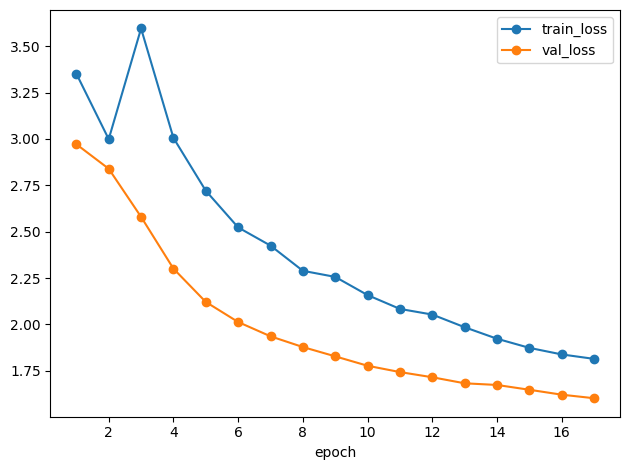

Restored: {'epoch': 17, 'stage': 'joint', 'train_loss': 1.8143832915459834, 'val_loss': 1.6022848631198434, 'seconds': 92.53674387931824}


In [36]:
reset_seed();net=VisualReportV2().to(DEVICE)
print('Visual RMS scale:',float(net.visual_scale))
import re
from torch.utils.data import WeightedRandomSampler
def positive(t,term):
    t=str(t).lower()
    for m in re.finditer(term,t):
        if not re.search(r'\b(no|without|negative for|resolved|clear of)\b',t[max(0,m.start()-40):m.start()]): return 1
    return 0
FIND=r'cardiomegaly|enlarged heart|atelectasis|opacit|consolidation|infiltrat|granuloma|nodule|mass|edema|pneumothorax|fracture|emphysema|hyperinflat'
abn=np.array([positive(t,FIND) for t in train.target_report])
weights=torch.tensor(np.where(abn==1,5.0,1.0),dtype=torch.double)
sampler=WeightedRandomSampler(weights,num_samples=len(train),replacement=True,generator=torch.Generator().manual_seed(SEED))
train_loader=DataLoader(train.to_dict('records'),batch_size=BATCH_SIZE,sampler=sampler,num_workers=0,collate_fn=collate)
print('abnormal share in train:',round(abn.mean(),3))

history=[];best=float('inf');bad_epochs=0;global_epoch=0
for stage,epochs in [('warmup',WARMUP_EPOCHS),('joint',JOINT_EPOCHS)]:
    net.text_model.requires_grad_(stage=='joint')
    groups=[{'params':net.adapter_parameters(),'lr':WARMUP_LR if stage=='warmup' else ADAPTER_LR}]
    if stage=='joint':groups.append({'params':net.text_model.parameters(),'lr':TEXT_LR})
    optimizer=torch.optim.AdamW(groups,weight_decay=.01)
    for epoch in range(epochs):
        global_epoch+=1;began=time.time();net.train()
        if stage=='warmup':net.text_model.eval()
        optimizer.zero_grad(set_to_none=True);total=0.;tokens=0
        for step,batch in enumerate(tqdm(train_loader,desc=f'{stage} {epoch+1}/{epochs}')):
            loss=net(**batch)
            assert torch.isfinite(loss), 'Nonfinite training loss'
            group_size=min(ACCUM,len(train_loader)-(step//ACCUM)*ACCUM)
            (loss/group_size).backward()
            n=int(batch['labels'].ne(-100).sum());total+=float(loss.detach())*n;tokens+=n
            if (step+1)%ACCUM==0 or step+1==len(train_loader):
                nn.utils.clip_grad_norm_(net.parameters(),1.);optimizer.step();optimizer.zero_grad(set_to_none=True)
        vl=loss_on(net,val)
        record={'epoch':global_epoch,'stage':stage,'train_loss':total/tokens,'val_loss':vl,'seconds':time.time()-began}
        history.append(record);print(record)
        pd.DataFrame(history).to_csv(OUT/'training_history.csv',index=False)
        if vl<best:
            best=vl;bad_epochs=0
            torch.save({k:v.detach().cpu().clone() for k,v in net.state_dict().items()},OUT/'best_v2.pt')
            (OUT/'selection.json').write_text(json.dumps(record,indent=2))
        elif stage=='joint':bad_epochs+=1
        if stage=='joint' and bad_epochs>=PATIENCE:break
    del optimizer;gc.collect();torch.cuda.empty_cache()
net.load_state_dict(torch.load(OUT/'best_v2.pt',map_location='cpu',weights_only=True));net.eval()
display(pd.DataFrame(history))
pd.DataFrame(history).plot(x='epoch',y=['train_loss','val_loss'],marker='o')
plt.tight_layout();plt.savefig(OUT/'loss_curves.png',dpi=160);plt.show()
print('Restored:',json.loads((OUT/'selection.json').read_text()))


## 07 | Full validation comparison, without test access
Use exactly the same references and deterministic beam settings as V1. Reuse saved V1 and retrieval outputs; no sklearn import or retrieval refit is needed. Metrics run in a separate process. BLEU uses 0–100; ROUGE-L/METEOR use 0–1. None measures clinical correctness.


In [37]:
new_reports=predict(net,val,'V2 validation reports')
result=val[['uid','indication','target_report']].copy()
result['generated_report']=new_reports
result['v1_report']=baseline.generated_report.tolist()
result['retrieved_report']=baseline.retrieved_report.tolist()
result.to_csv(OUT/'validation_predictions_v2.csv',index=False)
METRIC_SCRIPT=r"""
import sys,json,numpy as np,nltk,sacrebleu
from rouge_score import rouge_scorer
from nltk.translate.meteor_score import meteor_score
x=json.load(sys.stdin);r=x['references'];p=x['predictions']
nltk.download('wordnet',quiet=True);nltk.download('omw-1.4',quiet=True)
rouge=rouge_scorer.RougeScorer(['rougeL'],use_stemmer=True)
print(json.dumps({'bleu':sacrebleu.corpus_bleu(p,[r]).score,
'rougeL_f1':float(np.mean([rouge.score(a,b)['rougeL'].fmeasure for a,b in zip(r,p)])),
'meteor':float(np.mean([meteor_score([a.split()],b.split()) for a,b in zip(r,p)]))}))
"""
def metrics(references,predictions):
    process=subprocess.run([sys.executable,'-c',METRIC_SCRIPT],input=json.dumps({'references':list(references),'predictions':list(predictions)}),text=True,capture_output=True)
    if process.returncode:raise RuntimeError(process.stderr)
    return json.loads(process.stdout)
comparison=[]
for name,pred in [('V1',result.v1_report),('retrieval',result.retrieved_report),('V2',result.generated_report)]:
    comparison.append({'model':name,**metrics(result.target_report,pred),**diversity(pred)})
comparison=pd.DataFrame(comparison);display(comparison)
comparison.to_csv(OUT/'validation_comparison.csv',index=False)
for r in result.sample(n=8,random_state=SEED).itertuples():
    print('\nUID:',r.uid,'\nREFERENCE:',r.target_report,'\nV1:',r.v1_report,'\nV2:',r.generated_report)
review=result.sample(n=min(20,len(result)),random_state=SEED).copy()
for key in ['unsupported_finding','missed_finding','negation_error','reviewer_comment']:review[key]=''
review.to_csv(OUT/'manual_review.csv',index=False)


V2 validation reports:   0%|          | 0/180 [00:00<?, ?it/s]

,model,bleu,rougeL_f1,meteor,unique_reports,top_report_share
0,V1,10.349983,0.330740,0.231947,12,0.908078
1,retrieval,19.866274,0.354954,0.318319,241,0.030641
2,V2,18.196053,0.384662,0.331074,261,0.058496



UID: 3284 
REFERENCE: findings: the heart size and pulmonary vascularity appear within normal limits. the lungs are free of focal airspace disease. no pleural effusion or pneumothorax is seen. impression: 1. no evidence of active disease. 
V1: findings: the cardiomediastinal silhouette is normal in size and contour. the lungs are clear. there is no pneumothorax or pleural effusion. there is no acute bony abnormality. impression: no acute cardiopulmonary abnormality. 
V2: findings: the cardiomediastinal silhouette is normal in size. the lungs are clear. there is no pneumothorax or pleural effusion. there are no focal airspace consolidations. the heart size is normal. impression: no acute cardiopulmonary abnormality.

UID: 1448 
REFERENCE: findings: and lateral views of the chest were obtained on 02/010/ . the lung volumes are normal. the lungs are clear and there are no pleural effusions. there is stable mild tenting of the medial aspect of the right diaphragm. the mediastinum and pulm

## 08 | Paired validation image swaps

64 fixed validation studies and 3 seeded derangements (no study keeps its own images). All views, view types and the XRV tags move together with the images; each recipient keeps its own indication and reference report. A positive loss gap means the model relies on the image. It does not prove the content is correct.

V1 is not re-run here. Its earlier result on the same probe was: changed reports 0%, loss gap 0.007 (95% interval -0.029 to 0.043), meaning V1 ignored the image.

In [39]:
@torch.no_grad()
def individual_losses(network,frame):
    network.eval();values=[]
    for row in frame.to_dict('records'):
        loss=network(**collate([row]));assert torch.isfinite(loss);values.append(float(loss))
    return np.asarray(values)
probe=val.sample(n=min(64,len(val)),random_state=SEED).reset_index(drop=True)
assert len(probe)>1
permutations=[]
for seed in [42,43,44]:
    rng=np.random.default_rng(seed)
    while True:
        perm=rng.permutation(len(probe))
        if np.all(perm!=np.arange(len(probe))):break
    permutations.append(perm)

def swap_review(network,label):
    original_loss=individual_losses(network,probe)
    original_reports=predict(network,probe,label+' original')
    rows=[];deltas=[]
    for seed,perm in zip([42,43,44],permutations):
        swapped=probe.copy()
        swapped['image_names']=[list(probe.iloc[i].image_names) for i in perm]
        swapped['view_ids']=[list(probe.iloc[i].view_ids) for i in perm]
        swapped['input_text']=[b+'. image findings: '+tags_for(ns) for b,ns in zip(swapped.base_input_text,swapped.image_names)]
        other_loss=individual_losses(network,swapped)
        other_reports=predict(network,swapped,label+f' swapped {seed}')
        deltas.append(other_loss-original_loss)
        for i in range(len(probe)):
            rows.append({'model':label,'seed':seed,'uid':probe.iloc[i].uid,'donor_uid':probe.iloc[perm[i]].uid,
                         'original_loss':original_loss[i],'swapped_loss':other_loss[i],
                         'changed':norm(original_reports[i])!=norm(other_reports[i]),
                         'original_report':original_reports[i],'swapped_report':other_reports[i]})
    details=pd.DataFrame(rows);details.to_csv(OUT/f'{label}_image_swaps.csv',index=False)
    per_study=np.mean(deltas,axis=0);rng=np.random.default_rng(42)
    boot=[rng.choice(per_study,size=len(per_study),replace=True).mean() for _ in range(1000)]
    return {'model':label,'studies':len(probe),'swap_seeds':3,'changed_share':float(details.changed.mean()),
            'mean_study_loss_gap':float(per_study.mean()),'gap_lower95':float(np.quantile(boot,.025)),
            'gap_upper95':float(np.quantile(boot,.975))}
# Run sequentially to limit GPU memory.
v2_swap=swap_review(net,'V2')
swap_table=pd.DataFrame([v2_swap]);display(swap_table)
swap_table.to_csv(OUT/'image_swap_comparison.csv',index=False)

V2 original:   0%|          | 0/32 [00:00<?, ?it/s]

V2 swapped 42:   0%|          | 0/32 [00:00<?, ?it/s]

V2 swapped 43:   0%|          | 0/32 [00:00<?, ?it/s]

V2 swapped 44:   0%|          | 0/32 [00:00<?, ?it/s]

,model,studies,swap_seeds,changed_share,mean_study_loss_gap,gap_lower95,gap_upper95
0,V2,64,3,1.0,0.031878,0.013401,0.049532


## 07b | Finding counts and forced findings (classify then generate)

The first cell counts, for every saved run, how many reference findings the generated reports mention (keyword rule with simple negation).

With accurate tags the decoder still wrote few findings: on validation it mentioned cardiomegaly 8 times with 1 correct, although the classifier tagged it correctly in 24 studies. The decoder learned that writing a normal report is the safe choice.

The second cell adds a fixed sentence to the findings and impression when the classifier is confident, and removes sentences that contradict it (for example "heart size is normal" when cardiomegaly is added). A finding is forced only above the lowest threshold that reaches 60% precision on out-of-fold training predictions, with at least 10 training studies above it. Atelectasis and degenerative spine never reach that precision, so they are never forced. On validation the realized precision was lower than on train, around 45 to 50%. The step needs no training and changed 43 of 359 validation reports (36 opacity, 11 cardiomegaly, 4 emphysema, 1 effusion).

In [50]:
import re
def positive(t,term):
    t=str(t).lower()
    for m in re.finditer(term,t):
        if not re.search(r'\b(no|without|negative for|resolved|clear of)\b',t[max(0,m.start()-40):m.start()]): return 1
    return 0
terms={'cardiomegaly':'cardiomegaly|enlarged heart|heart is enlarged','atelectasis':'atelectasis',
       'opacity':'opacit|consolidation|infiltrat','effusion':'effusion','granuloma':'granuloma'}
def finding_row(label,refs,preds):
    row={'model':label}
    for k,term in terms.items():
        y=np.array([positive(t,term) for t in refs]);p=np.array([positive(t,term) for t in preds])
        row[k]=f'{int((y&p).sum())}/{int(y.sum())} found, {int(p.sum())} written'
    return row
rows=[finding_row('V1',result.target_report,result.v1_report),
      finding_row('retrieval',result.target_report,result.retrieved_report)]
for csv in sorted(Path(OUTPUT_ROOT).glob('*/validation_predictions_v2.csv')):
    d=pd.read_csv(csv,dtype={'uid':str},keep_default_na=False)
    rows.append(finding_row(csv.parent.name,d.target_report,d.generated_report))
pd.set_option('display.max_colwidth',None);display(pd.DataFrame(rows))

,model,cardiomegaly,atelectasis,opacity,effusion,granuloma
0,V1,"0/38 found, 0 written","0/39 found, 0 written","0/78 found, 0 written","1/72 found, 16 written","0/42 found, 0 written"
1,retrieval,"2/38 found, 23 written","9/39 found, 39 written","18/78 found, 72 written","22/72 found, 76 written","8/42 found, 38 written"
2,20261025_184014_913116,"0/38 found, 0 written","0/39 found, 0 written","0/78 found, 0 written","17/72 found, 59 written","0/42 found, 0 written"
3,20261025_201120_037523,"1/38 found, 1 written","0/39 found, 0 written","0/78 found, 0 written","19/72 found, 76 written","0/42 found, 3 written"
4,20261026_172351_817659,"3/38 found, 5 written","0/39 found, 0 written","1/78 found, 2 written","25/72 found, 136 written","1/42 found, 4 written"
5,20261026_180944_731991,"9/38 found, 19 written","0/39 found, 0 written","5/78 found, 14 written","27/72 found, 140 written","5/42 found, 18 written"
6,20261028_104045_835510,"3/38 found, 6 written","1/39 found, 5 written","0/78 found, 8 written","38/72 found, 162 written","1/42 found, 6 written"
7,20261028_113222_436989,"1/38 found, 8 written","1/39 found, 6 written","7/78 found, 32 written","26/72 found, 155 written","0/42 found, 14 written"


In [60]:
# Classify-then-generate: add a finding sentence when the IU classifier is confident.
# Confidence thresholds come from train out-of-fold predictions only (precision >= 0.6).
FORCE={'cardiomegaly':('the heart is enlarged.','cardiomegaly.'),
       'atelectasis':('there is mild atelectasis.','mild atelectasis.'),
       'opacity':('there is a focal airspace opacity.','focal airspace opacity.'),
       'effusion':('there is a small pleural effusion.','small pleural effusion.'),
       'emphysema':('the lungs are hyperexpanded, consistent with emphysema.','emphysema.'),
       'degenerative spine':('there are degenerative changes of the thoracic spine.','degenerative changes of the spine.')}
def precision_thr(p,y,target=0.6,min_tagged=10):
    for t in np.sort(np.unique(p)):
        pred=p>=t
        if pred.sum()<min_tagged: break
        if (pred&(y==1)).sum()/pred.sum()>=target: return float(t)
    return None
FTHR={k:precision_thr(OOF[:,j],Ytr[:,j]) for j,k in enumerate(TAG_NAMES)}
print('force thresholds (None = never forced):',{k:(None if v is None else round(v,3)) for k,v in FTHR.items()})

def contradicts(s,k):
    if k=='cardiomegaly':
        return bool(re.search(r'(heart|cardiac|cardiomediastinal|mediastinal)[^.]*(normal|unremarkable|within normal limits)',s))
    return any(re.search(NEG,s[:m.start()]) for m in re.finditer(FINDINGS[k],s))
def split_sents(t): return [s.strip() for s in re.split(r'(?<=\.)\s+',t) if s.strip()]
def enforce(report,p):
    r=str(report).lower().strip()
    i=r.find('impression:')
    fnd=(r[:i] if i>=0 else r).replace('findings:','',1).strip();imp=r[i+len('impression:'):].strip() if i>=0 else ''
    F,I=split_sents(fnd),split_sents(imp);added=[]
    for j,k in enumerate(TAG_NAMES):
        t=FTHR.get(k)
        if t is None or p[j]<t or k not in FORCE or mentions(r,FINDINGS[k]): continue
        F=[s for s in F if not contradicts(s,k)]+[FORCE[k][0]];I=[FORCE[k][1]]+[s for s in I if not contradicts(s,k)];added.append(k)
    return 'findings: '+' '.join(F)+' impression: '+' '.join(I),added

hyb=[enforce(r,p) for r,p in zip(result.generated_report,Pva)]
result['hybrid_report']=[h for h,_ in hyb]
print('reports changed:',sum(bool(a) for _,a in hyb),'| added per finding:',pd.Series([k for _,a in hyb for k in a]).value_counts().to_dict())
cmp=pd.DataFrame([{'model':'V2',**metrics(result.target_report,result.generated_report),**diversity(result.generated_report)},
                  {'model':'V2 + forced findings',**metrics(result.target_report,result.hybrid_report),**diversity(result.hybrid_report)}])
display(cmp)
display(pd.DataFrame([finding_row('V2',result.target_report,result.generated_report),
                      finding_row('V2 + forced findings',result.target_report,result.hybrid_report)]))
result.to_csv(OUT/'validation_predictions_hybrid.csv',index=False);cmp.to_csv(OUT/'validation_comparison_hybrid.csv',index=False)
for r in result[result.hybrid_report!=result.generated_report].head(3).itertuples():
    print('\nREFERENCE:',r.target_report,'\nV2:',r.generated_report,'\nHYBRID:',r.hybrid_report)

force thresholds (None = never forced): {'cardiomegaly': 0.847, 'atelectasis': None, 'opacity': 0.725, 'effusion': 0.943, 'emphysema': 0.927, 'degenerative spine': None}
reports changed: 43 | added per finding: {'opacity': 36, 'cardiomegaly': 11, 'emphysema': 4, 'effusion': 1}


,model,bleu,rougeL_f1,meteor,unique_reports,top_report_share
0,V2,18.196053,0.384662,0.331074,261,0.058496
1,V2 + forced findings,17.994754,0.382217,0.329318,265,0.058496


,model,cardiomegaly,atelectasis,opacity,effusion,granuloma
0,V2,"1/38 found, 8 written","1/39 found, 6 written","7/78 found, 32 written","26/72 found, 155 written","0/42 found, 14 written"
1,V2 + forced findings,"9/38 found, 18 written","1/39 found, 6 written","23/78 found, 65 written","24/72 found, 151 written","0/42 found, 14 written"



REFERENCE: findings: the heart and mediastinal contours are stable. aorta is calcified and tortuous, compatible with atherosclerotic disease. since the prior study, there's been interval development of left lower lobe airspace disease. the right lung is clear. impression: 1. interval development of left lower lobe airspace disease. this may be due to atelectasis or infiltrate. 
V2: findings: the cardiomediastinal silhouette is within normal limits for size and contour. the lungs are free of focal airspace disease, pleural effusion, or pneumothorax. there is no focal consolidation, effusion or focal consolidation. impression: 1. no acute cardiopulmonary abnormality. 
HYBRID: findings: the cardiomediastinal silhouette is within normal limits for size and contour. there is a focal airspace opacity. impression: focal airspace opacity. 1. no acute cardiopulmonary abnormality.

REFERENCE: findings: pa and moderate loss of the chest demonstrate stable moderate cardiomediastinal silhouette wi

In [52]:
# Log this run to MLflow (SQLite DB kept on Drive).
%pip -q install mlflow
import mlflow, re
DRIVE_DB=Path('/content/drive/MyDrive/Team29/mlflow.db');LOCAL_DB=Path('/content/mlflow.db')
ARTIFACTS='file:/content/drive/MyDrive/Team29/mlflow_artifacts'
if DRIVE_DB.exists(): shutil.copy2(DRIVE_DB,LOCAL_DB)
mlflow.set_tracking_uri(f'sqlite:///{LOCAL_DB}')
EXP='team29-report-generation'
if mlflow.get_experiment_by_name(EXP) is None: mlflow.create_experiment(EXP,artifact_location=ARTIFACTS)
mlflow.set_experiment(EXP)

RUN_NAME='v2_iuclf_forced_oversample'+str(int(float(weights.max())))   # rename for a new experiment
already=mlflow.search_runs(filter_string=f"tags.run_folder = '{OUT.name}'")
if len(already):
    print('Already logged:',OUT.name)
else:
    def positive(t,term):
        t=str(t).lower()
        for m in re.finditer(term,t):
            if not re.search(r'\b(no|without|negative for|resolved|clear of)\b',t[max(0,m.start()-40):m.start()]): return 1
        return 0
    TERMS={'cardiomegaly':'cardiomegaly|enlarged heart|heart is enlarged','atelectasis':'atelectasis',
           'opacity':'opacit|consolidation|infiltrat','granuloma':'granuloma'}
    v2=comparison[comparison.model=='V2'].iloc[0];sw=swap_table[swap_table.model=='V2'].iloc[0]
    sel=json.loads((OUT/'selection.json').read_text())
    with mlflow.start_run(run_name=RUN_NAME):
        mlflow.set_tags({'run_folder':OUT.name,'kind':'experiment','test_logged':'no'})
        mlflow.log_params({'base_model':BASE_MODEL,'visual_tokens':VISUAL_TOKENS,'batch_size':BATCH_SIZE,'accum':ACCUM,
            'warmup_epochs':WARMUP_EPOCHS,'joint_epochs':JOINT_EPOCHS,'warmup_lr':WARMUP_LR,'adapter_lr':ADAPTER_LR,
            'text_lr':TEXT_LR,'patience':PATIENCE,'seed':SEED,'features':'resnet18','tags':f'iu_classifier_on_{XRV_WEIGHTS}','tag_findings':','.join(TAG_NAMES),'forced_findings':'precision>=0.6 on train OOF',
            'oversample':float(weights.max()),'num_beams':4,'no_repeat_ngram_size':3,'repetition_penalty':1.2})
        for r in history: mlflow.log_metrics({'train_loss':r['train_loss'],'val_loss':r['val_loss']},step=int(r['epoch']))
        mlflow.log_metrics({'best_val_loss':sel['val_loss'],'best_epoch':sel['epoch'],
            'val_bleu':v2.bleu,'val_rougeL':v2.rougeL_f1,'val_meteor':v2.meteor,
            'val_unique_reports':v2.unique_reports,'val_top_report_share':v2.top_report_share,
            'swap_changed_share':sw.changed_share,'swap_loss_gap':sw.mean_study_loss_gap,
            'swap_gap_lower95':sw.gap_lower95,'swap_gap_upper95':sw.gap_upper95})
        for k,term in TERMS.items():
            y=np.array([positive(t,term) for t in result.target_report]);p=np.array([positive(t,term) for t in result.generated_report])
            mlflow.log_metrics({f'val_{k}_found':int((y&p).sum()),f'val_{k}_written':int(p.sum()),f'val_{k}_cases':int(y.sum())})
        if 'hybrid_report' in result.columns:
            h=cmp.set_index('model').loc['V2 + forced findings']
            mlflow.log_metrics({'val_forced_bleu':h.bleu,'val_forced_rougeL':h.rougeL_f1,'val_forced_meteor':h.meteor,
                                'val_forced_unique_reports':h.unique_reports,'val_forced_top_report_share':h.top_report_share})
            for k,term in TERMS.items():
                y=np.array([positive(t,term) for t in result.target_report]);p=np.array([positive(t,term) for t in result.hybrid_report])
                mlflow.log_metrics({f'val_forced_{k}_found':int((y&p).sum()),f'val_forced_{k}_written':int(p.sum())})
        for f in ['iu_tag_classifier_val.csv','validation_comparison_hybrid.csv']:
            if (OUT/f).exists(): mlflow.log_artifact(str(OUT/f))
        for f in ['loss_curves.png','validation_comparison.csv','image_swap_comparison.csv','training_history.csv','selection.json']:
            if (OUT/f).exists(): mlflow.log_artifact(str(OUT/f))
    print('Logged',OUT.name,'as',RUN_NAME)
shutil.copy2(LOCAL_DB,DRIVE_DB);print('Saved MLflow DB to',DRIVE_DB)

Already logged: 20261028_113222_436989
Saved MLflow DB to /content/drive/MyDrive/Team29/mlflow.db


## 09 | Export the final model and verify reload

Saves the T5 weights, tokenizer, visual adapter, a copy of the V1 ResNet18 encoder, the IU tag classifier (`iu_tag_classifier.pt`) and `config.json` with the tag names and thresholds, the forced-finding thresholds and sentences, the decoding settings and the training choices. `inference_v2.py` rebuilds the full pipeline without this notebook: prompt with classifier tags, generation, then forced findings.

The check confirms that the saved pipeline reproduces every validation prompt, the classifier probabilities, every forced-finding edit on the saved validation reports, and one full generated report.

`generate_features` takes the 512-D ResNet18 vectors and the 1024-D CheXpert pooled features per image. `xrv_pooled_from_image` computes the pooled features from a raw image. Raw-image use also needs the exact ResNet18 preprocessing from the V1 preprocessing notebook for the 512-D vectors.

In [61]:
MODEL_DIR=OUT/'candidate_generator';MODEL_DIR.mkdir(exist_ok=True)
net.text_model.save_pretrained(MODEL_DIR/'text_model',safe_serialization=True)
tokenizer.save_pretrained(MODEL_DIR/'tokenizer')
visual_state={k:v.detach().cpu() for k,v in net.state_dict().items() if not k.startswith('text_model.')}
torch.save(visual_state,MODEL_DIR/'visual_adapter.pt')
encoder_path=OLD/'resnet18_encoder.pt'
if not encoder_path.exists():encoder_path=OLD/'saved_generator/resnet18_encoder.pt'
assert encoder_path.is_file(), 'Missing saved ResNet18 encoder'
shutil.copy2(encoder_path,MODEL_DIR/'resnet18_encoder.pt')
torch.save({'weight':CLF.weight.detach().cpu(),'bias':CLF.bias.detach().cpu(),
            'mu':torch.from_numpy(np.asarray(MU,dtype='float32')),'sd':torch.from_numpy(np.asarray(SD,dtype='float32'))},
           MODEL_DIR/'iu_tag_classifier.pt')
config={'visual_tokens':VISUAL_TOKENS,'max_input':MAX_INPUT,'max_target':MAX_TARGET,'seed':SEED,
        'warmup_epochs':WARMUP_EPOCHS,'joint_epochs':JOINT_EPOCHS,'warmup_lr':WARMUP_LR,
        'adapter_lr':ADAPTER_LR,'text_lr':TEXT_LR,'source':str(OLD),
        'status':'final: ResNet18 global features + IU-classifier tags on CheXpert-only XRV features + forced findings + abnormal oversampling',
        'tags':{'mode':'iu_classifier','xrv_weights':XRV_WEIGHTS,'names':TAG_NAMES,'thresholds':[float(t) for t in THR],
                'max_tags':3,'l2':float(LAM),'patterns':{k:FINDINGS[k] for k in TAG_NAMES},'negation':NEG},
        'forced_findings':{'precision_target':0.6,'thresholds':{k:(None if v is None else float(v)) for k,v in FTHR.items()},
                           'sentences':{k:list(v) for k,v in FORCE.items()}},
        'oversample_abnormal_weight':float(weights.max()),
        'decoding':{'num_beams':4,'no_repeat_ngram_size':3,'repetition_penalty':1.2},
        'source_manifest_hashes':{f:hashlib.sha256((OLD/f).read_bytes()).hexdigest() for f in ['train_studies.json','val_studies.json','image_audit.csv']},
        'selection':json.loads((OUT/'selection.json').read_text()),'test_previously_seen':True}
(MODEL_DIR/'config.json').write_text(json.dumps(config,indent=2))
import importlib.metadata as metadata
vers={}
for p in ['torch','torchvision','transformers','tokenizers','numpy','pandas','nltk','sacrebleu','rouge-score','torchxrayvision']:
    try: vers[p]=metadata.version(p)
    except Exception: vers[p]='not installed'
(OUT/'versions.json').write_text(json.dumps(vers,indent=2))
print('Exported to',MODEL_DIR)

Exported to /content/drive/MyDrive/Team29/report_generation_v2/20261028_113222_436989/candidate_generator


In [65]:
INFERENCE_SOURCE = r"""
import json, re
from pathlib import Path
import numpy as np
import torch
from torch import nn
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
BASE_MODEL="google/flan-t5-small"
VISUAL_TOKENS=4
MAX_TARGET=256
class VisualReportV2(nn.Module):
    def __init__(self,path=BASE_MODEL):
        super().__init__()
        self.text_model=AutoModelForSeq2SeqLM.from_pretrained(path,use_safetensors=True)
        d=self.text_model.config.d_model
        self.d=d; self.k=VISUAL_TOKENS
        self.projector=nn.Sequential(nn.LayerNorm(512),nn.Linear(512,512),nn.GELU(),nn.Linear(512,self.k*d))
        self.view_embedding=nn.Embedding(4,d,padding_idx=0)
        self.visual_norm=nn.LayerNorm(d)
        with torch.no_grad():
            scale=self.text_model.get_input_embeddings().weight[:4096].float().square().mean().sqrt()
        self.register_buffer('visual_scale',scale.clone())
    def encode(self,vectors,views,image_mask,input_ids,attention_mask):
        b,v,_=vectors.shape
        visual=self.projector(vectors).reshape(b,v,self.k,self.d)
        visual=visual+self.view_embedding(views).unsqueeze(2)
        visual=self.visual_norm(visual)*self.visual_scale
        visual=visual.reshape(b,v*self.k,self.d)
        mask=image_mask.repeat_interleave(self.k,dim=1)
        text=self.text_model.get_input_embeddings()(input_ids)
        return torch.cat([visual,text],1),torch.cat([mask,attention_mask],1)
    def forward(self,labels,**inputs):
        embeddings,mask=self.encode(**inputs)
        return self.text_model(inputs_embeds=embeddings,attention_mask=mask,labels=labels,use_cache=False).loss
    @torch.no_grad()
    def generate(self,**inputs):
        self.eval();embeddings,mask=self.encode(**inputs)
        return self.text_model.generate(inputs_embeds=embeddings,attention_mask=mask,max_new_tokens=MAX_TARGET,num_beams=4,no_repeat_ngram_size=3,repetition_penalty=1.2,do_sample=False)
    def adapter_parameters(self):
        return [p for n,p in self.named_parameters() if not n.startswith('text_model.')]

_XRV={}
def xrv_pooled_from_image(path,device='cpu',weights='densenet121-res224-chex'):
    # 1024-D pooled DenseNet121 features for one grayscale chest X-ray (use config['tags']['xrv_weights']).
    import torchxrayvision as xrv, torchvision
    from PIL import Image
    if weights not in _XRV:
        _XRV[weights]=(xrv.models.DenseNet(weights=weights).to(device).eval(),
                       torchvision.transforms.Compose([xrv.datasets.XRayCenterCrop(),xrv.datasets.XRayResizer(224)]))
    enc,tf=_XRV[weights]
    img=np.array(Image.open(path).convert('L'),dtype=np.float32)
    img=tf(xrv.datasets.normalize(img,255)[None])
    with torch.no_grad():
        fmap=torch.relu(enc.features(torch.from_numpy(img)[None].float().to(device)))
    return fmap.mean((2,3))[0].cpu().numpy().astype('float32')

class SavedGenerator:
    def __init__(self, folder, device=None):
        global VISUAL_TOKENS,MAX_TARGET
        folder=Path(folder);self.config=json.loads((folder/'config.json').read_text())
        VISUAL_TOKENS=self.config['visual_tokens'];MAX_TARGET=self.config['max_target']
        self.device=torch.device(device or ('cuda' if torch.cuda.is_available() else 'cpu'))
        self.tokenizer=AutoTokenizer.from_pretrained(folder/'tokenizer',local_files_only=True)
        self.net=VisualReportV2(folder/'text_model')
        adapter=torch.load(folder/'visual_adapter.pt',map_location='cpu',weights_only=True)
        expected={k for k in self.net.state_dict() if not k.startswith('text_model.')}
        assert set(adapter)==expected
        self.net.load_state_dict(adapter,strict=False);self.net.to(self.device).eval()
        c=torch.load(folder/'iu_tag_classifier.pt',map_location='cpu',weights_only=True)
        self.W,self.b=c['weight'],c['bias'];self.mu,self.sd=c['mu'].numpy(),c['sd'].numpy()
        t=self.config['tags'];self.names=t['names'];self.thr=t['thresholds'];self.patterns=t['patterns'];self.neg=t['negation']
        f=self.config['forced_findings'];self.fthr=f['thresholds'];self.force=f['sentences']
    def finding_probs(self,xrv_pooled):
        x=((np.mean(np.asarray(xrv_pooled,dtype='float32'),0)-self.mu)/self.sd).astype('float32')[None]
        with torch.no_grad(): return torch.sigmoid(nn.functional.linear(torch.from_numpy(x),self.W,self.b))[0].numpy()
    def make_tags(self,p):
        found=sorted([(p[j]-self.thr[j],self.names[j]) for j in range(len(self.names)) if p[j]>=self.thr[j]],reverse=True)
        return ', '.join(n for _,n in found[:self.config['tags']['max_tags']]) or 'none'
    def build_text(self,indication,xrv_pooled):
        note=re.sub(r'\b[xX]{2,}\b',' ',str(indication));note=' '.join(note.split())
        base='generate chest x-ray report. indication: '+(note or 'not provided')
        return base+'. image findings: '+self.make_tags(self.finding_probs(xrv_pooled))
    def _mentions(self,text,term):
        for sent in re.split(r'[.;]',str(text).lower()):
            for m in re.finditer(term,sent):
                if not re.search(self.neg,sent[:m.start()]): return 1
        return 0
    def _contradicts(self,s,k):
        if k=='cardiomegaly':
            return bool(re.search(r'(heart|cardiac|cardiomediastinal|mediastinal)[^.]*(normal|unremarkable|within normal limits)',s))
        return any(re.search(self.neg,s[:m.start()]) for m in re.finditer(self.patterns[k],s))
    def enforce(self,report,p):
        split=lambda t:[s.strip() for s in re.split(r'(?<=\.)\s+',t) if s.strip()]
        r=str(report).lower().strip()
        i=r.find('impression:')
        fnd=(r[:i] if i>=0 else r).replace('findings:','',1).strip();imp=r[i+len('impression:'):].strip() if i>=0 else ''
        F,I=split(fnd),split(imp);added=[]
        for j,k in enumerate(self.names):
            t=self.fthr.get(k)
            if t is None or p[j]<t or k not in self.force or self._mentions(r,self.patterns[k]): continue
            F=[s for s in F if not self._contradicts(s,k)]+[self.force[k][0]];I=[self.force[k][1]]+[s for s in I if not self._contradicts(s,k)];added.append(k)
        return 'findings: '+' '.join(F)+' impression: '+' '.join(I),added
    @torch.inference_mode()
    def generate_features(self,vectors,view_ids,indication='',xrv_pooled=None,forced=True):
        assert xrv_pooled is not None, 'Pass one 1024-D pooled XRV vector per image (see xrv_pooled_from_image)'
        vectors=np.asarray(vectors,dtype='float32')
        assert vectors.ndim==2 and vectors.shape[1]==512 and len(vectors)==len(view_ids)==len(xrv_pooled)>0
        assert np.isfinite(vectors).all() and all(int(v) in [1,2,3] for v in view_ids)
        text=self.build_text(indication,xrv_pooled)
        inputs=self.tokenizer(text,return_tensors='pt',truncation=True,max_length=self.config['max_input']).to(self.device)
        output=self.net.generate(vectors=torch.tensor(vectors[None],device=self.device),
            views=torch.tensor([view_ids],device=self.device),image_mask=torch.ones(1,len(vectors),dtype=torch.long,device=self.device),**inputs)
        report=self.tokenizer.decode(output[0],skip_special_tokens=True)
        return self.enforce(report,self.finding_probs(xrv_pooled))[0] if forced else report
"""
(OUT/'inference_v2.py').write_text(INFERENCE_SOURCE)
print('Wrote',OUT/'inference_v2.py')

Wrote /content/drive/MyDrive/Team29/report_generation_v2/20261028_113222_436989/inference_v2.py


In [66]:
import importlib.util
assert 'hybrid_report' in result.columns, 'Run section 07b (forced findings) first'
net.to(DEVICE).eval()
row=val.iloc[0]
plain=predict(net,val.iloc[:1],'Reload reference')[0]
expected=enforce(plain,Pva[0])[0]
net.cpu();gc.collect();torch.cuda.empty_cache()
try:
    spec=importlib.util.spec_from_file_location('inference_v2',OUT/'inference_v2.py')
    mod=importlib.util.module_from_spec(spec);spec.loader.exec_module(mod)
    restored=mod.SavedGenerator(MODEL_DIR,device=str(DEVICE))
    pooled=lambda ns:[xrv_pooled[n] for n in ns]
    P=np.stack([restored.finding_probs(pooled(ns)) for ns in val.image_names])
    print('max |prob difference| on val:',float(np.abs(P-Pva).max()))
    mism=[r.uid for r in val.itertuples() if restored.build_text(r.indication,pooled(r.image_names))!=r.input_text]
    print('prompt mismatches on val:',len(mism),mism[:5])
    assert not mism, 'Saved prompt builder differs from training prompts'
    edits=[u for u,g_,h,p in zip(result.uid,result.generated_report,result.hybrid_report,P) if restored.enforce(g_,p)[0]!=h]
    print('forced-finding mismatches on saved val reports:',len(edits),edits[:5])
    assert not edits, 'Saved forced-finding step differs from section 07b'
    actual=restored.generate_features(np.stack([features[n] for n in row.image_names]),row.view_ids,row.indication,xrv_pooled=pooled(row.image_names))
    print('Prompt:  ',row.input_text)
    print('Expected:',expected)
    print('Actual:  ',actual)
    assert actual==expected, 'Export mismatch: inspect before using the saved candidate'
    print('Final pipeline reload verified.')
    del restored
finally:
    gc.collect();torch.cuda.empty_cache();net.to(DEVICE)

Reload reference:   0%|          | 0/1 [00:00<?, ?it/s]

max |prob difference| on val: 2.980232238769531e-07
prompt mismatches on val: 0 []
forced-finding mismatches on saved val reports: 0 []
Prompt:   generate chest x-ray report. indication: preop chest x- .. image findings: degenerative spine
Expected: findings: the cardiomediastinal silhouette is within normal limits for size and contour. the lungs are clear. no focal consolidation, pneumothorax, or pleural effusion. impression: no acute cardiopulmonary abnormality.
Actual:   findings: the cardiomediastinal silhouette is within normal limits for size and contour. the lungs are clear. no focal consolidation, pneumothorax, or pleural effusion. impression: no acute cardiopulmonary abnormality.
Final pipeline reload verified.


## 09b | Final test, run once

Evaluates the trained model on the 362 test studies, with and without forced findings. Test tags come from the IU classifier fitted on train. Results go to `test_results_hybrid/` in the run folder, and the cell refuses to regenerate once results exist.

In [55]:
# Final test for the IU-classifier run, plain and with forced findings. Run once.
TEST_OUT=OUT/'test_results_hybrid';TEST_OUT.mkdir(exist_ok=True)
if (TEST_OUT/'test_comparison.csv').exists():
    print('Already evaluated:');display(pd.read_csv(TEST_OUT/'test_comparison.csv'));display(pd.read_csv(TEST_OUT/'test_findings.csv'))
else:
    test=test_manifest.copy();test['uid']=test.uid.astype(str)
    assert not set(test.uid)&(set(train.uid)|set(val.uid))
    test['base_input_text']=test['input_text']
    test['input_text']=[b+'. image findings: '+tags_for(ns) for b,ns in zip(test.base_input_text,test.image_names)]
    Pte=clf_prob(CLF,((study_X(test)-MU)/SD).astype('float32'))
    net.to(DEVICE).eval()
    test_loss=loss_on(net,test);reports=predict(net,test,'Test reports')
    out=test[['uid','indication','input_text','target_report']].copy();out['generated_report']=reports
    out['hybrid_report']=[enforce(r,p)[0] for r,p in zip(reports,Pte)]
    out.to_csv(TEST_OUT/'test_predictions.csv',index=False)
    comp=pd.DataFrame([{'model':'V2','split':'test','device':DEVICE.type,'studies':len(test),'token_loss':test_loss,
                        **metrics(out.target_report,out.generated_report),**diversity(out.generated_report)},
                       {'model':'V2 + forced findings','split':'test','device':DEVICE.type,'studies':len(test),'token_loss':test_loss,
                        **metrics(out.target_report,out.hybrid_report),**diversity(out.hybrid_report)}])
    find=pd.DataFrame([finding_row('V2',out.target_report,out.generated_report),
                       finding_row('V2 + forced findings',out.target_report,out.hybrid_report)])
    find.to_csv(TEST_OUT/'test_findings.csv',index=False);comp.to_csv(TEST_OUT/'test_comparison.csv',index=False)
    display(comp);display(find)
    print('Saved to',TEST_OUT)

Already evaluated:


,model,split,device,studies,token_loss,bleu,rougeL_f1,meteor,unique_reports,top_report_share
0,V2,test,cuda,362,1.627883,18.425743,0.392881,0.337997,250,0.082873
1,V2 + forced findings,test,cuda,362,1.627883,18.473801,0.391365,0.338550,255,0.082873


,model,cardiomegaly,atelectasis,opacity,effusion,granuloma
0,V2,"2/23 found, 6 written","2/45 found, 8 written","3/70 found, 25 written","34/70 found, 156 written","0/49 found, 12 written"
1,V2 + forced findings,"7/23 found, 14 written","2/45 found, 7 written","15/70 found, 53 written","33/70 found, 152 written","0/49 found, 12 written"


## 10 | Results and interpretation

**Final model:** run `20261028_113222_436989`, IU-classifier tags plus forced findings.

### Validation (359 studies)

| Model | BLEU | ROUGE-L | METEOR | Unique reports | Most repeated | Swap loss gap |
|---|---|---|---|---|---|---|
| V1 | 10.3 | 0.331 | 0.232 | 12 | 90.8% | 0.007 |
| Retrieval baseline | 19.9 | 0.355 | 0.318 | 241 | 3.1% | n/a |
| V2, no tags | 16.2 | 0.398 | 0.312 | n/a | 17.8% | 0.030 |
| V2 + OpenI-trained tags (leaked) | 18.1 | 0.381 | 0.335 | 307 | 1.9% | 0.031 |
| V2 + raw CheXpert tags | 17.2 | 0.385 | 0.324 | 299 | 1.7% | 0.031 |
| V2 + IU-classifier tags | 18.2 | 0.385 | 0.331 | 261 | 5.8% | 0.032 |
| **+ forced findings (final)** | **18.0** | **0.382** | **0.329** | **265** | **5.8%** | **0.032** |

Finding-level counts (found / reference cases, total mentions):

| Finding | Retrieval | Leaked tags | Raw CheXpert | IU classifier | **Final** |
|---|---|---|---|---|---|
| Cardiomegaly | 2/38, 23 | 9/38, 19 | 3/38, 6 | 1/38, 8 | **9/38, 18** |
| Atelectasis | 9/39, 39 | 0/39, 0 | 1/39, 5 | 1/39, 6 | **1/39, 6** |
| Opacity | 18/78, 72 | 5/78, 14 | 0/78, 8 | 7/78, 32 | **23/78, 65** |
| Granuloma | 8/42, 38 | 5/42, 18 | 1/42, 6 | 0/42, 14 | **0/42, 14** |

Image-swap test (final model): reports changed in 100% of swaps; loss gap 0.032 (95% interval 0.013 to 0.050).

### Test (362 studies)

| Model | BLEU | ROUGE-L | METEOR | Unique reports | Most repeated | Cardiomegaly | Atelectasis | Opacity |
|---|---|---|---|---|---|---|---|---|
| Leaked tags (CPU) | 17.3 | 0.377 | 0.326 | 314 | 1.7% | 7/23, 15 | 1/45, 1 | 9/70, 21 |
| Raw CheXpert tags | 18.4 | 0.388 | 0.333 | 281 | 2.2% | 5/23, 6 | 2/45, 2 | 3/70, 14 |
| IU-classifier tags | 18.4 | 0.393 | 0.338 | 250 | 8.3% | 2/23, 6 | 2/45, 8 | 3/70, 25 |
| **+ forced findings (final)** | **18.5** | **0.391** | **0.339** | **255** | **8.3%** | **7/23, 14** | **2/45, 7** | **15/70, 53** |

### Reading

- **Repeated reports.** Solved by the new adapter and abnormal oversampling: the most repeated report fell from 90.8% (V1) to under 10%. The final model repeats more than the leaked one (5.8% vs 1.9% on validation), so diversity is the main cost of the final setup.
- **Image reliance.** Every V2 run changes its report when the images change, with a positive loss gap whose interval stays above zero.
- **Leakage.** Removing the OpenI-trained tagger barely changed text metrics but cut cardiomegaly detection from 9 to 3 of 38 on validation, so most of the earlier detection came from the leak.
- **Recovery without leakage.** The train-only classifier made the tags accurate, and forced findings turned them into report text. On test, the final model finds 7 of 23 cardiomegaly cases with 7 of 14 mentions correct (about 1 expected by chance) and 15 of 70 opacity cases with 15 of 53 mentions correct (about 10 expected by chance).
- **Still weak.** Most abnormal findings are missed, atelectasis barely improves, and granuloma is lost because its classifier was too weak to keep. The model drafts plausible normal reports; it is not reliable for detecting disease.

Effusion counts are left out because the keyword rule misreads long negated lists.

**Experiments that did not help.** Replacing the 4 global tokens with 16 XRV spatial patches plus a score token lowered every metric and weakened image reliance, likely because the new layers had too little data (1,690 training studies).

### Leakage checks (the two cells below)

- Image tagger: switched from `densenet121-res224-all` (trained on OpenI) to the CheXpert-only weights.
- Image features: the V1 ResNet18 encoder matches the ImageNet weights tensor for tensor (120 of 120), so it was never fine-tuned on IU images.
- IU classifier, its thresholds and the forced-finding thresholds use training studies only; training tags are out-of-fold.
- Exact duplicate images: none across splits (SHA-256 audit).
- Near-duplicate images: none above cosine 0.98 between validation or test images and any training image.
- Model inputs contain no report text; 2 to 3% of indications name a finding, at the same rate in every split.

**Remaining limits.** Splits are by study, not by patient, and IU X-Ray has no patient IDs, so repeat visits of one patient may fall in different splits. Validation was used for several design choices and is optimistic. The test split was evaluated four times during development (V1, leaked tagger, raw CheXpert tagger, final model). No choice was tuned on test results, but the final test numbers are not from an untouched holdout. Dropping nodule and granuloma used a train-only rule, but the idea came after seeing their validation results.

In [56]:
# Classify-then-generate: add a finding sentence when the IU classifier is confident.
# Confidence thresholds come from train out-of-fold predictions only (precision >= 0.6).
FORCE={'cardiomegaly':('the heart is enlarged.','cardiomegaly.'),
       'atelectasis':('there is mild atelectasis.','mild atelectasis.'),
       'opacity':('there is a focal airspace opacity.','focal airspace opacity.'),
       'effusion':('there is a small pleural effusion.','small pleural effusion.'),
       'emphysema':('the lungs are hyperexpanded, consistent with emphysema.','emphysema.'),
       'degenerative spine':('there are degenerative changes of the thoracic spine.','degenerative changes of the spine.')}
def precision_thr(p,y,target=0.6,min_tagged=10):
    for t in np.sort(np.unique(p)):
        pred=p>=t
        if pred.sum()<min_tagged: break
        if (pred&(y==1)).sum()/pred.sum()>=target: return float(t)
    return None
FTHR={k:precision_thr(OOF[:,j],Ytr[:,j]) for j,k in enumerate(TAG_NAMES)}
print('force thresholds (None = never forced):',{k:(None if v is None else round(v,3)) for k,v in FTHR.items()})

def contradicts(s,k):
    if k=='cardiomegaly':
        return bool(re.search(r'(heart|cardiac|cardiomediastinal|mediastinal)[^.]*(normal|unremarkable|within normal limits)',s))
    return any(re.search(NEG,s[:m.start()]) for m in re.finditer(FINDINGS[k],s))
def split_sents(t): return [s.strip() for s in re.split(r'(?<=\.)\s+',t) if s.strip()]
def enforce(report,p):
    r=str(report).lower().strip()
    i=r.find('impression:')
    fnd=(r[:i] if i>=0 else r).replace('findings:','',1).strip();imp=r[i+len('impression:'):].strip() if i>=0 else ''
    F,I=split_sents(fnd),split_sents(imp);added=[]
    for j,k in enumerate(TAG_NAMES):
        t=FTHR.get(k)
        if t is None or p[j]<t or k not in FORCE or mentions(r,FINDINGS[k]): continue
        F=[s for s in F if not contradicts(s,k)]+[FORCE[k][0]];I=[FORCE[k][1]]+[s for s in I if not contradicts(s,k)];added.append(k)
    return 'findings: '+' '.join(F)+' impression: '+' '.join(I),added

hyb=[enforce(r,p) for r,p in zip(result.generated_report,Pva)]
result['hybrid_report']=[h for h,_ in hyb]
print('reports changed:',sum(bool(a) for _,a in hyb),'| added per finding:',pd.Series([k for _,a in hyb for k in a]).value_counts().to_dict())
cmp=pd.DataFrame([{'model':'V2',**metrics(result.target_report,result.generated_report),**diversity(result.generated_report)},
                  {'model':'V2 + forced findings',**metrics(result.target_report,result.hybrid_report),**diversity(result.hybrid_report)}])
display(cmp)
display(pd.DataFrame([finding_row('V2',result.target_report,result.generated_report),
                      finding_row('V2 + forced findings',result.target_report,result.hybrid_report)]))
result.to_csv(OUT/'validation_predictions_hybrid.csv',index=False);cmp.to_csv(OUT/'validation_comparison_hybrid.csv',index=False)
for r in result[result.hybrid_report!=result.generated_report].head(3).itertuples():
    print('\nREFERENCE:',r.target_report,'\nV2:',r.generated_report,'\nHYBRID:',r.hybrid_report)

force thresholds (None = never forced): {'cardiomegaly': 0.847, 'atelectasis': None, 'opacity': 0.725, 'effusion': 0.943, 'emphysema': 0.927, 'degenerative spine': None}
reports changed: 43 | added per finding: {'opacity': 36, 'cardiomegaly': 11, 'emphysema': 4, 'effusion': 1}


,model,bleu,rougeL_f1,meteor,unique_reports,top_report_share
0,V2,18.196053,0.384662,0.331074,261,0.058496
1,V2 + forced findings,17.994754,0.382217,0.329318,265,0.058496


,model,cardiomegaly,atelectasis,opacity,effusion,granuloma
0,V2,"1/38 found, 8 written","1/39 found, 6 written","7/78 found, 32 written","26/72 found, 155 written","0/42 found, 14 written"
1,V2 + forced findings,"9/38 found, 18 written","1/39 found, 6 written","23/78 found, 65 written","24/72 found, 151 written","0/42 found, 14 written"



REFERENCE: findings: the heart and mediastinal contours are stable. aorta is calcified and tortuous, compatible with atherosclerotic disease. since the prior study, there's been interval development of left lower lobe airspace disease. the right lung is clear. impression: 1. interval development of left lower lobe airspace disease. this may be due to atelectasis or infiltrate. 
V2: findings: the cardiomediastinal silhouette is within normal limits for size and contour. the lungs are free of focal airspace disease, pleural effusion, or pneumothorax. there is no focal consolidation, effusion or focal consolidation. impression: 1. no acute cardiopulmonary abnormality. 
HYBRID: findings: the cardiomediastinal silhouette is within normal limits for size and contour. there is a focal airspace opacity. impression: focal airspace opacity. 1. no acute cardiopulmonary abnormality.

REFERENCE: findings: pa and moderate loss of the chest demonstrate stable moderate cardiomediastinal silhouette wi

In [57]:
# Final test for the IU-classifier run, plain and with forced findings. Run once.
TEST_OUT=OUT/'test_results_hybrid';TEST_OUT.mkdir(exist_ok=True)
if (TEST_OUT/'test_comparison.csv').exists():
    print('Already evaluated:');display(pd.read_csv(TEST_OUT/'test_comparison.csv'));display(pd.read_csv(TEST_OUT/'test_findings.csv'))
else:
    test=test_manifest.copy();test['uid']=test.uid.astype(str)
    assert not set(test.uid)&(set(train.uid)|set(val.uid))
    test['base_input_text']=test['input_text']
    test['input_text']=[b+'. image findings: '+tags_for(ns) for b,ns in zip(test.base_input_text,test.image_names)]
    Pte=clf_prob(CLF,((study_X(test)-MU)/SD).astype('float32'))
    net.to(DEVICE).eval()
    test_loss=loss_on(net,test);reports=predict(net,test,'Test reports')
    out=test[['uid','indication','input_text','target_report']].copy();out['generated_report']=reports
    out['hybrid_report']=[enforce(r,p)[0] for r,p in zip(reports,Pte)]
    out.to_csv(TEST_OUT/'test_predictions.csv',index=False)
    comp=pd.DataFrame([{'model':'V2','split':'test','device':DEVICE.type,'studies':len(test),'token_loss':test_loss,
                        **metrics(out.target_report,out.generated_report),**diversity(out.generated_report)},
                       {'model':'V2 + forced findings','split':'test','device':DEVICE.type,'studies':len(test),'token_loss':test_loss,
                        **metrics(out.target_report,out.hybrid_report),**diversity(out.hybrid_report)}])
    find=pd.DataFrame([finding_row('V2',out.target_report,out.generated_report),
                       finding_row('V2 + forced findings',out.target_report,out.hybrid_report)])
    find.to_csv(TEST_OUT/'test_findings.csv',index=False);comp.to_csv(TEST_OUT/'test_comparison.csv',index=False)
    display(comp);display(find)
    print('Saved to',TEST_OUT)

Already evaluated:


,model,split,device,studies,token_loss,bleu,rougeL_f1,meteor,unique_reports,top_report_share
0,V2,test,cuda,362,1.627883,18.425743,0.392881,0.337997,250,0.082873
1,V2 + forced findings,test,cuda,362,1.627883,18.473801,0.391365,0.338550,255,0.082873


,model,cardiomegaly,atelectasis,opacity,effusion,granuloma
0,V2,"2/23 found, 6 written","2/45 found, 8 written","3/70 found, 25 written","34/70 found, 156 written","0/49 found, 12 written"
1,V2 + forced findings,"7/23 found, 14 written","2/45 found, 7 written","15/70 found, 53 written","33/70 found, 152 written","0/49 found, 12 written"


## 11 | Experiment tracking with MLflow

All experiments are recorded in one MLflow experiment, `team29-report-generation`, so runs can be compared side by side without rerunning any training.

**Storage.** MLflow 3.17.2 with a SQLite backend (`Team29/mlflow.db`). The older folder-based `mlruns` store is no longer accepted by this MLflow version. Artifacts are kept in `Team29/mlflow_artifacts`. In Colab the database is copied to `/content` while it is in use and copied back to Drive afterwards, because SQLite can lock or corrupt files on the Drive mount.

**Runs.** Six runs were logged:

| Run | What it is |
|---|---|
| `baseline_V1` | Earlier V1 model, saved validation outputs |
| `baseline_retrieval` | Nearest-neighbour report retrieval, saved validation outputs |
| `v2_resnet` | New visual adapter with ResNet18 features, no tags |
| `v2_tags` | Adds XRV finding tags to the prompt |
| `v2_tags_oversample3` | Adds 3x oversampling of abnormal studies |
| `v2_tags_oversample5_FINAL` | 5x oversampling, the selected model |

The earlier runs were added after training by a backfill cell that reads each run folder in `report_generation_v2/`. New training runs are logged by the cell placed after the finding-level table. The XRV spatial-patch experiment is missing because its folder was overwritten by the `v2_tags` run.

**What each run stores.**
- Parameters: base model, visual tokens, batch size and accumulation, warmup and joint epochs, learning rates, patience, seed, feature type, tag rule (`xrv_q0.88`), oversampling weight and decoding settings.
- Metrics per epoch: `train_loss` and `val_loss`.
- Validation metrics: `best_val_loss`, `best_epoch`, `val_bleu`, `val_rougeL`, `val_meteor`, `val_unique_reports`, `val_top_report_share`.
- Image reliance: `swap_changed_share`, `swap_loss_gap` and its 95% interval.
- Finding counts for cardiomegaly, atelectasis, opacity and granuloma: `val_<finding>_found`, `_written` and `_cases`.
- Artifacts: `loss_curves.png`, `training_history.csv`, `validation_comparison.csv`, `image_swap_comparison.csv`, `selection.json`.

**Test results.** Only the final run holds test metrics (`test_bleu`, `test_rougeL`, `test_meteor`, `test_token_loss`, `test_top## 11 | Experiment tracking with MLflow

All experiments are recorded in one MLflow experiment, `team29-report-generation`, so runs can be compared side by side without rerunning any training.

**Storage.** MLflow 3.17.2 with a SQLite backend (`Team29/mlflow.db`). The older folder-based `mlruns` store is no longer accepted by this MLflow version. Artifacts are kept in `Team29/mlflow_artifacts`. In Colab the database is copied to `/content` while it is in use and copied back to Drive afterwards, because SQLite can lock or corrupt files on the Drive mount.

**Runs.**

| Run | What it is |
|---|---|
| `baseline_V1` | Earlier V1 model, saved validation outputs |
| `baseline_retrieval` | Nearest-neighbour report retrieval, saved validation outputs |
| `v2_resnet` | New visual adapter with ResNet18 features, no tags |
| `v2_tags` | Adds XRV finding tags to the prompt |
| `v2_tags_oversample3` | Adds 3x oversampling of abnormal studies |
| `v2_tags_oversample5_LEAKED` | 5x oversampling; tags from the OpenI-trained XRV weights (leaked) |
| `v2_chextags_oversample5` | Same, with raw CheXpert-only XRV tags |
| `v2_iuclf_forced_FINAL` | IU-classifier tags plus forced findings, the final model |

The earlier runs were added after training by a backfill cell that reads each run folder in `report_generation_v2/`. New training runs are logged by the cell placed after the finding-level table. The XRV spatial-patch experiment is missing because its folder was overwritten by the `v2_tags` run.

**What each run stores.**
- Parameters: base model, visual tokens, batch size and accumulation, warmup and joint epochs, learning rates, patience, seed, feature type, tag rule (`xrv_q0.88`), oversampling weight and decoding settings.
- Metrics per epoch: `train_loss` and `val_loss`.
- Validation metrics: `best_val_loss`, `best_epoch`, `val_bleu`, `val_rougeL`, `val_meteor`, `val_unique_reports`, `val_top_report_share`.
- Image reliance: `swap_changed_share`, `swap_loss_gap` and its 95% interval.
- Finding counts for cardiomegaly, atelectasis, opacity and granuloma: `val_<finding>_found`, `_written` and `_cases`.
- Artifacts: `loss_curves.png`, `training_history.csv`, `validation_comparison.csv`, `image_swap_comparison.csv`, `selection.json`.

**Test results.** Only the final runs hold test metrics (`test_bleu`, `test_rougeL`, `test_meteor`, `test_token_loss`, `test_top_report_share` and the finding counts), plus the test CSVs under `test_results/`. Its tags are `test_logged = yes`, `test_device = cpu` and `test_previously_seen = true`. The other runs carry `test_logged = no`. Keeping test numbers off the experimental runs stops them from being used to pick a model.

**Note on `v2_resnet`.** Its validation numbers in MLflow (BLEU 16.2, top report share 17.8%) differ from the first figures reported for that run (BLEU 17.3, 21.4%). The run's predictions were regenerated after the full decoding settings (`no_repeat_ngram_size=3`, `repetition_penalty=1.2`) were applied, and MLflow reads the latest files. Its swap-test result predates that regeneration.

**Tagger leakage.** Runs `v2_tags`, `v2_tags_oversample3` and `v2_tags_oversample5_FINAL` used the `densenet121-res224-all` XRV weights, which were trained on OpenI (IU X-Ray). Their tag-based results, including the test numbers on the FINAL run, are not trustworthy and carry the tag `xrv_leakage = openi`. The rerun with the CheXpert-only tagger is logged as `v2_chextags_oversample5`.

**Opening the UI in Colab.** Start the server with `--disable-security-middleware`, otherwise MLflow blocks requests from the Colab proxy domain, and open it with `google.colab.output.serve_kernel_port_as_window(5000)`. Stop any older server on port 5000 first, and wait about 45 seconds for startup. The link is private to the Colab session and closes with it._report_share` and the finding counts), plus the test CSVs under `test_results/`. Its tags are `test_logged = yes`, `test_device = cpu` and `test_previously_seen = true`. The other runs carry `test_logged = no`. Keeping test numbers off the experimental runs stops them from being used to pick a model.

**Note on `v2_resnet`.** Its validation numbers in MLflow (BLEU 16.2, top report share 17.8%) differ from the first figures reported for that run (BLEU 17.3, 21.4%). The run's predictions were regenerated after the full decoding settings (`no_repeat_ngram_size=3`, `repetition_penalty=1.2`) were applied, and MLflow reads the latest files. Its swap-test result predates that regeneration.

**Tagger leakage.** Runs `v2_tags`, `v2_tags_oversample3` and `v2_tags_oversample5_FINAL` used the `densenet121-res224-all` XRV weights, which were trained on OpenI (IU X-Ray). Their tag-based results, including the test numbers on the FINAL run, are not trustworthy and carry the tag `xrv_leakage = openi`. The rerun with the CheXpert-only tagger is logged as `v2_chextags_oversample5`.

**Opening the UI in Colab.** Start the server with `--disable-security-middleware`, otherwise MLflow blocks requests from the Colab proxy domain, and open it with `google.colab.output.serve_kernel_port_as_window(5000)`. Stop any older server on port 5000 first, and wait about 45 seconds for startup. The link is private to the Colab session and closes with it.

In [67]:
%pip -q install mlflow
import json, re, numpy as np, pandas as pd, mlflow
from pathlib import Path
from google.colab import drive
drive.mount('/content/drive')

ROOT=Path('/content/drive/MyDrive/Team29/report_generation_v2')
import shutil
DRIVE_DB=Path('/content/drive/MyDrive/Team29/mlflow.db')
LOCAL_DB=Path('/content/mlflow.db')
ARTIFACTS='file:/content/drive/MyDrive/Team29/mlflow_artifacts'
if DRIVE_DB.exists() and not LOCAL_DB.exists(): shutil.copy2(DRIVE_DB,LOCAL_DB)
mlflow.set_tracking_uri(f'sqlite:///{LOCAL_DB}')
EXP='team29-report-generation'
if mlflow.get_experiment_by_name(EXP) is None:
    mlflow.create_experiment(EXP,artifact_location=ARTIFACTS)
mlflow.set_experiment(EXP)

KNOWN={
 '20261025_184014_913116':{'name':'v2_resnet','features':'resnet18','tags':'none','oversample':1.0},
 '20261025_201120_037523':{'name':'v2_tags','features':'resnet18','tags':'xrv_q0.88','oversample':1.0},
 '20261026_172351_817659':{'name':'v2_tags_oversample3','features':'resnet18','tags':'xrv_q0.88','oversample':3.0},
 '20261026_180944_731991':{'name':'v2_tags_oversample5_FINAL','features':'resnet18','tags':'xrv_q0.88','oversample':5.0},
}
COMMON={'base_model':'google/flan-t5-small','visual_tokens':4,'batch_size':2,'accum':4,'warmup_epochs':2,
        'joint_epochs':15,'warmup_lr':1e-3,'adapter_lr':3e-4,'text_lr':1e-5,'patience':3,'seed':42,
        'num_beams':4,'no_repeat_ngram_size':3,'repetition_penalty':1.2}

def positive(t,term):
    t=str(t).lower()
    for m in re.finditer(term,t):
        if not re.search(r'\b(no|without|negative for|resolved|clear of)\b',t[max(0,m.start()-40):m.start()]): return 1
    return 0
TERMS={'cardiomegaly':'cardiomegaly|enlarged heart|heart is enlarged','atelectasis':'atelectasis',
       'opacity':'opacit|consolidation|infiltrat','granuloma':'granuloma'}
def finding_metrics(refs,preds,prefix='val'):
    out={}
    for k,term in TERMS.items():
        y=np.array([positive(t,term) for t in refs]);p=np.array([positive(t,term) for t in preds])
        out[f'{prefix}_{k}_found']=int((y&p).sum());out[f'{prefix}_{k}_written']=int(p.sum());out[f'{prefix}_{k}_cases']=int(y.sum())
    return out

done={r.data.tags.get('run_folder') for r in mlflow.search_runs(output_format='list')}
baselines_logged='baselines' in done
for folder in sorted(p for p in ROOT.iterdir() if p.is_dir()):
    comp_path=folder/'validation_comparison.csv'
    if not comp_path.exists(): print('skip (no results):',folder.name);continue
    comp=pd.read_csv(comp_path)
    if not baselines_logged:
        for _,b in comp[comp.model.isin(['V1','retrieval'])].iterrows():
            with mlflow.start_run(run_name=f'baseline_{b.model}'):
                mlflow.set_tags({'run_folder':'baselines','kind':'baseline'})
                mlflow.log_metrics({'val_bleu':b.bleu,'val_rougeL':b.rougeL_f1,'val_meteor':b.meteor,
                                    'val_unique_reports':b.unique_reports,'val_top_report_share':b.top_report_share})
                pred=pd.read_csv(folder/'validation_predictions_v2.csv',keep_default_na=False)
                col='v1_report' if b.model=='V1' else 'retrieved_report'
                mlflow.log_metrics(finding_metrics(pred.target_report,pred[col]))
        baselines_logged=True
    if folder.name in done: print('already logged:',folder.name);continue
    info=KNOWN.get(folder.name,{'name':'unlabeled_'+folder.name})
    v2=comp[comp.model=='V2'].iloc[0]
    with mlflow.start_run(run_name=info['name']):
        mlflow.set_tags({'run_folder':folder.name,'kind':'experiment','test_logged':'no'})
        mlflow.log_params({**COMMON,**{k:v for k,v in info.items() if k!='name'}})
        mlflow.log_metrics({'val_bleu':v2.bleu,'val_rougeL':v2.rougeL_f1,'val_meteor':v2.meteor,
                            'val_unique_reports':v2.unique_reports,'val_top_report_share':v2.top_report_share})
        hist=folder/'training_history.csv'
        if hist.exists():
            for r in pd.read_csv(hist).itertuples():
                mlflow.log_metrics({'train_loss':r.train_loss,'val_loss':r.val_loss},step=int(r.epoch))
        sel=folder/'selection.json'
        if sel.exists():
            s=json.loads(sel.read_text());mlflow.log_metrics({'best_val_loss':s['val_loss'],'best_epoch':s['epoch']})
        swap=folder/'image_swap_comparison.csv'
        if swap.exists():
            sw=pd.read_csv(swap);sw=sw[sw.model=='V2'].iloc[0]
            mlflow.log_metrics({'swap_changed_share':sw.changed_share,'swap_loss_gap':sw.mean_study_loss_gap,
                                'swap_gap_lower95':sw.gap_lower95,'swap_gap_upper95':sw.gap_upper95})
        pred=folder/'validation_predictions_v2.csv'
        if pred.exists():
            d=pd.read_csv(pred,keep_default_na=False);mlflow.log_metrics(finding_metrics(d.target_report,d.generated_report))
        for f in ['loss_curves.png','validation_comparison.csv','image_swap_comparison.csv','training_history.csv','selection.json']:
            if (folder/f).exists(): mlflow.log_artifact(str(folder/f))
    print('logged:',folder.name,'->',info['name'])

runs=mlflow.search_runs()
cols=['tags.mlflow.runName','metrics.val_bleu','metrics.val_rougeL','metrics.val_meteor','metrics.val_top_report_share',
      'metrics.val_cardiomegaly_found','metrics.val_cardiomegaly_written','metrics.swap_loss_gap']
display(runs[[c for c in cols if c in runs.columns]].sort_values('tags.mlflow.runName'))
shutil.copy2(LOCAL_DB,DRIVE_DB)
print('Saved MLflow DB to',DRIVE_DB)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
skip (no results): 20261025_180627_546876
already logged: 20261025_184014_913116
already logged: 20261025_201120_037523
already logged: 20261026_172351_817659
already logged: 20261026_180944_731991
skip (no results): 20261027_092837_712676
skip (no results): 20261027_095214_704995
already logged: 20261028_104045_835510
already logged: 20261028_113222_436989


,tags.mlflow.runName,metrics.val_bleu,metrics.val_rougeL,metrics.val_meteor,metrics.val_top_report_share,metrics.val_cardiomegaly_found,metrics.val_cardiomegaly_written,metrics.swap_loss_gap
7,baseline_V1,10.349983,0.330740,0.231947,0.908078,0.0,0.0,NaN
6,baseline_retrieval,19.866274,0.354954,0.318319,0.030641,2.0,23.0,NaN
1,v2_chextags_oversample5,17.175023,0.385159,0.324315,0.016713,3.0,6.0,0.030985
0,v2_iuclf_oversample55,18.196053,0.384662,0.331074,0.058496,1.0,8.0,0.031878
5,v2_resnet,16.167711,0.397602,0.311503,0.178273,0.0,0.0,0.030006
4,v2_tags,15.444007,0.386445,0.307975,0.119777,1.0,1.0,0.035368
3,v2_tags_oversample3,16.267067,0.396238,0.324690,0.055710,3.0,5.0,0.028750
2,v2_tags_oversample5_FINAL,18.148363,0.381224,0.334786,0.019499,9.0,19.0,0.031360


Saved MLflow DB to /content/drive/MyDrive/Team29/mlflow.db


In [68]:
shutil.copy2(LOCAL_DB,DRIVE_DB)
print('Saved MLflow DB to',DRIVE_DB)

Saved MLflow DB to /content/drive/MyDrive/Team29/mlflow.db


In [69]:
# Log the final test results (test_results_hybrid) on the final run in MLflow. Run once.
%pip -q install mlflow
import mlflow, shutil, pandas as pd, re
from pathlib import Path
DRIVE_DB=Path('/content/drive/MyDrive/Team29/mlflow.db');LOCAL_DB=Path('/content/mlflow.db')
shutil.copy2(DRIVE_DB,LOCAL_DB)
mlflow.set_tracking_uri(f'sqlite:///{LOCAL_DB}');mlflow.set_experiment('team29-report-generation')

FINAL_FOLDER='20261028_113222_436989'   # the IU-classifier run; change only if you train a new final run
TEST_OUT=Path('/content/drive/MyDrive/Team29/report_generation_v2')/FINAL_FOLDER/'test_results_hybrid'
runs=mlflow.search_runs(filter_string=f"tags.run_folder = '{FINAL_FOLDER}'")
assert len(runs)==1, f'Expected one run for {FINAL_FOLDER}, found {len(runs)}'
run_id=runs.run_id.iloc[0];client=mlflow.MlflowClient()
client.set_tag(run_id,'mlflow.runName','v2_iuclf_forced_FINAL')
if runs['tags.test_logged'].iloc[0]=='yes':
    print('Test already logged on',run_id)
else:
    comp=pd.read_csv(TEST_OUT/'test_comparison.csv').set_index('model')
    find=pd.read_csv(TEST_OUT/'test_findings.csv').set_index('model')
    with mlflow.start_run(run_id=run_id):
        for model,prefix in [('V2 + forced findings','test'),('V2','test_plain')]:
            c=comp.loc[model]
            mlflow.log_metrics({f'{prefix}_bleu':c.bleu,f'{prefix}_rougeL':c.rougeL_f1,f'{prefix}_meteor':c.meteor,
                                f'{prefix}_unique_reports':c.unique_reports,f'{prefix}_top_report_share':c.top_report_share})
            for k in ['cardiomegaly','atelectasis','opacity','granuloma']:
                found,cases,written=map(int,re.findall(r'\d+',find.loc[model,k]))
                mlflow.log_metrics({f'{prefix}_{k}_found':found,f'{prefix}_{k}_cases':cases,f'{prefix}_{k}_written':written})
        mlflow.log_metrics({'test_token_loss':comp.token_loss.iloc[0],'test_studies':comp.studies.iloc[0]})
        mlflow.set_tags({'test_logged':'yes','test_device':comp.device.iloc[0],'test_previously_seen':'true','final_model':'yes',
                         'test_metrics':'test_* = with forced findings, test_plain_* = decoder only'})
        for f in ['test_comparison.csv','test_findings.csv','test_predictions.csv']:
            mlflow.log_artifact(str(TEST_OUT/f),artifact_path='test_results_hybrid')
    print('Logged test metrics on',run_id)
for folder,name in [('20261026_180944_731991','v2_tags_oversample5_LEAKED'),('20261028_104045_835510','v2_chextags_oversample5')]:
    for r in mlflow.search_runs(filter_string=f"tags.run_folder = '{folder}'",output_format='list'):
        client.set_tag(r.info.run_id,'mlflow.runName',name);client.set_tag(r.info.run_id,'final_model','no')
shutil.copy2(LOCAL_DB,DRIVE_DB);print('Saved MLflow DB to',DRIVE_DB)

Logged test metrics on 2d5911e8d1474ecf8a52e11bcd440bc1
Saved MLflow DB to /content/drive/MyDrive/Team29/mlflow.db


In [70]:
# Mark the runs whose tags came from the OpenI-trained XRV weights (run once).
%pip -q install mlflow
import mlflow, shutil
from pathlib import Path
DRIVE_DB=Path('/content/drive/MyDrive/Team29/mlflow.db');LOCAL_DB=Path('/content/mlflow.db')
shutil.copy2(DRIVE_DB,LOCAL_DB)
mlflow.set_tracking_uri(f'sqlite:///{LOCAL_DB}');mlflow.set_experiment('team29-report-generation')
LEAKED=['20261025_201120_037523','20261026_172351_817659','20261026_180944_731991']
client=mlflow.MlflowClient()
for folder in LEAKED:
    for r in mlflow.search_runs(filter_string=f"tags.run_folder = '{folder}'",output_format='list'):
        client.set_tag(r.info.run_id,'xrv_leakage','openi')
        client.set_tag(r.info.run_id,'xrv_weights','densenet121-res224-all')
        print('marked',r.data.tags.get('mlflow.runName'),folder)
shutil.copy2(LOCAL_DB,DRIVE_DB);print('Saved MLflow DB to',DRIVE_DB)

marked v2_tags 20261025_201120_037523
marked v2_tags_oversample3 20261026_172351_817659
marked v2_tags_oversample5_LEAKED 20261026_180944_731991
Saved MLflow DB to /content/drive/MyDrive/Team29/mlflow.db


In [71]:
# Open the MLflow UI from Colab (reads Team29/mlflow.db from Drive)
from google.colab import drive, output
drive.mount('/content/drive')
%pip -q install mlflow==3.17.2
import shutil, subprocess, time
shutil.copy2('/content/drive/MyDrive/Team29/mlflow.db','/content/mlflow.db')
!pkill -f "mlflow" ; fuser -k 5000/tcp ; sleep 3
log=open('/content/mlflow_ui.log','w')
proc=subprocess.Popen(['mlflow','ui','--backend-store-uri','sqlite:////content/mlflow.db',
                       '--host','0.0.0.0','--port','5000','--workers','1','--disable-security-middleware'],stdout=log,stderr=log)
time.sleep(45)
txt=open('/content/mlflow_ui.log').read()
print('running' if proc.poll() is None and 'Address already in use' not in txt else 'problem:\n'+txt[-1500:])
output.serve_kernel_port_as_window(5000)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
^C
running
Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>